# Industrial Investment RL — Scientific Analysis & Publication Figures

**Machine Learning Techniques II · Mission-Based Reinforcement Learning Summative**  
**Source:** four *native TorchRL* training methods (DQN, REINFORCE, PPO, A2C), 10 configurations each, 1,000 × 24-step training episodes per configuration.  
**What this notebook does:** reads the **existing** CSVs and `.pt` files, validates completeness, creates all key visualizations and tables requested by the assignment/report template, **replays already-selected checkpoints** on the fixed 2024 seeds for paired diagnostics, visualizes a representative investment pathway, and exports report-ready scientific discussion notes.

> **No retraining. No model selection using 2024.** Original model selection is fixed from 2016–2023 historical validation. The 2024 import signals are a *single held-out observed year* used to initialize simulated 24-month scenarios; resulting rewards, capital and employment are **synthetic outputs**, not realized Rwandan economic returns.

### Local execution (Windows + VS Code, no Colab)

1. Save this notebook as `notebooks/scientific_analysis.ipynb` inside your existing repository.
2. From the repository's PowerShell terminal, run **once**:
   ```powershell
   uv add --dev ipykernel pandas matplotlib scipy
   uv sync
   ```
   This records notebook analysis packages in `pyproject.toml` and `uv.lock` for reproducibility; it does **not** change the trained models.
3. Open the notebook in VS Code and select the project's **`.venv` Python kernel** in the top-right kernel selector.
4. Use **Run All**. It finds the project root automatically whether the kernel starts in `notebooks/` or the repository root.
5. All figures are saved as **300 dpi PNG + vector PDF** under `analysis_outputs/figures/`. Tables and scientific notes are written under `analysis_outputs/tables/` and `analysis_outputs/notes/`.

**Before Run All:** make sure `logs/training/sweep_summary.csv`, `logs/training/final_2024_evaluation.csv`, all 40 per-run episode logs, and all four selected `.pt` files exist locally. Push the `notebooks/` file and generated `analysis_outputs/` after reviewing the outputs.

**Assignment alignment:** reward/cumulative-reward plots; DQN TD loss; policy entropy/stability; all 40 hyperparameter results; evidence-based *episodes to near-stability* heuristic; 2024 generalization and baselines; representative investment behavior. **The required 3D/2D interactive simulation is a separate deliverable; static notebook plots do not replace it.**

## 1. Setup, reproducibility, and output directories

Only one optional setting is available: `REPO_ROOT_OVERRIDE` (leave `None` for automatic detection). Replay of 2024 uses the **already selected** four actors, never updates their weights, and does not change the model choice.

In [1]:
from __future__ import annotations

import os, sys, json, platform, subprocess, hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

try:
    import scipy
except ImportError as exc:
    raise ImportError("Install analysis dependencies with: uv add --dev ipykernel pandas matplotlib scipy") from exc

REPO_ROOT_OVERRIDE = None     # Example: r"D:\path\to\Gaddiel_Irakoze__rl_summative"
RUN_DETAILED_2024_REPLAY = True  # Uses existing final checkpoints, never retrains
PLOT_DPI = 300
SEED_START, N_SEEDS = 60_000, 100
ALGORITHMS = ['dqn','reinforce','ppo','a2c']
DISPLAY_NAMES = {'dqn':'DQN','reinforce':'REINFORCE','ppo':'PPO','a2c':'A2C',
                 'rule_based':'Rule-Based','always_hold':'Always Hold','random_valid':'Random Valid'}
COLORS = {'dqn':'#2563eb','reinforce':'#d97706','ppo':'#059669','a2c':'#7c3aed',
          'rule_based':'#475569','always_hold':'#94a3b8','random_valid':'#b45309'}

candidates = ([Path(REPO_ROOT_OVERRIDE)] if REPO_ROOT_OVERRIDE else
              [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent])
ROOT = next((p.resolve() for p in candidates
             if (p/'logs/training/sweep_summary.csv').is_file() and (p/'pyproject.toml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot locate repository root. Set REPO_ROOT_OVERRIDE in this cell.")
# TradeSignalEnv uses data/processed relative paths; important if VS Code starts in notebooks/.
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
OUT = ROOT/'analysis_outputs'
FIG = OUT/'figures'; TABLES = OUT/'tables'; NOTES = OUT/'notes'
for folder in (FIG,TABLES,NOTES): folder.mkdir(parents=True,exist_ok=True)

plt.rcParams.update({'figure.dpi':125,'savefig.dpi':PLOT_DPI,'font.size':10,
                     'axes.titlesize':12,'axes.labelsize':10,'grid.alpha':0.2,
                     'axes.spines.top':False,'axes.spines.right':False})
FIGURE_INDEX = []
def save_figure(fig, stem, caption):
    fig.savefig(FIG/f'{stem}.png', dpi=PLOT_DPI, bbox_inches='tight', facecolor='white')
    fig.savefig(FIG/f'{stem}.pdf', bbox_inches='tight', facecolor='white')
    FIGURE_INDEX.append({'figure':stem,'caption':caption,'png':f'figures/{stem}.png',
                         'pdf':f'figures/{stem}.pdf'})
    plt.show()
    plt.close(fig)

def git_hash():
    try:
        return subprocess.run(['git','rev-parse','HEAD'],cwd=ROOT,capture_output=True,
                              text=True,check=True).stdout.strip()
    except Exception: return 'not available'

print('Repository:',ROOT)
print('Git commit:',git_hash())
print('Python:',platform.python_version(),'NumPy:',np.__version__,
      'pandas:',pd.__version__,'Matplotlib:',plt.matplotlib.__version__ if hasattr(plt,'matplotlib') else 'installed')
print('Export directory:',OUT)

Matplotlib is building the font cache; this may take a moment.


Repository: D:\Alu docs\BSE Courses\ML Techniques II\Summative\Gaddiel_Irakoze__rl_summative
Git commit: 740807ceb94cc424b05c4474acd21420629e6519
Python: 3.11.5 NumPy: 2.4.6 pandas: 3.1.1 Matplotlib: 3.11.2
Export directory: D:\Alu docs\BSE Courses\ML Techniques II\Summative\Gaddiel_Irakoze__rl_summative\analysis_outputs


## 2. Load and audit the complete 40-run experiment

**Stop on mismatched or incomplete evidence.** All 40 named configurations must exist; each must have exactly 1,000 episodes of 24 decisions, finite cumulative rewards, and matching saved results. DQN's initial loss entries may be `NaN` during replay warm-up and are not numerical crashes.

In [2]:
SWEEP_PATH = ROOT/'logs/training/sweep_summary.csv'
FINAL_PATH = ROOT/'logs/training/final_2024_evaluation.csv'
sweep = pd.read_csv(SWEEP_PATH)
final = pd.read_csv(FINAL_PATH)
assert len(sweep)==40, f'Expected 40 sweep rows, found {len(sweep)}'
assert sweep['run_id'].nunique()==40, 'Duplicate run identifiers'
assert sweep['algorithm'].value_counts().reindex(ALGORITHMS).eq(10).all(), 'Need 10 runs per algorithm'
assert set(final.algorithm)==set(ALGORITHMS+['always_hold','random_valid','rule_based'])

history = {}
quality_rows = []
for record in sweep.itertuples(index=False):
    run_id, algorithm = record.run_id, record.algorithm
    d = ROOT/'logs/training'/algorithm/run_id
    ep_path, summary_path = d/'episodes.csv', d/'summary.json'
    assert ep_path.is_file() and summary_path.is_file(), f'Missing log for {run_id}'
    ep = pd.read_csv(ep_path)
    summary = json.loads(summary_path.read_text(encoding='utf-8'))
    assert len(ep)==1000, f'{run_id}: expected 1000 episodes; found {len(ep)}'
    assert ep['episode'].astype(int).tolist()==list(range(1,1001)), f'{run_id}: episode numbering'
    assert (ep['steps']==24).all(), f'{run_id}: not all episodes are 24 decisions'
    assert (ep['env_steps'].iloc[-1]==24000), f'{run_id}: env steps mismatch'
    assert np.isfinite(ep['reward']).all(), f'{run_id}: nonfinite rewards'
    assert np.isclose(summary['validation_mean_reward'], record.validation_mean_reward, atol=1e-8)
    assert summary['train_episodes']==1000
    checkpoint = ROOT/'models'/algorithm/f'{run_id}.pt'
    assert checkpoint.is_file(), f'{run_id}: missing checkpoint'
    bad_loss = int((~np.isfinite(ep['loss'])).sum())
    bad_entropy = int((~np.isfinite(ep['entropy'])).sum()) if 'entropy' in ep else None
    assert bad_loss<=12 if algorithm=='dqn' else bad_loss==0, f'{run_id}: unexpected missing losses'
    if algorithm!='dqn':
        assert bad_entropy==0, f'{run_id}: nonfinite entropy'
    history[run_id]=ep
    quality_rows.append({'run_id':run_id,'algorithm':algorithm,'episodes':len(ep),
                         'steps':int(ep.steps.sum()),'nonfinite_reward':0,
                         'nonfinite_loss':bad_loss,'nonfinite_entropy':bad_entropy,
                         'checkpoint_bytes':checkpoint.stat().st_size})

quality = pd.DataFrame(quality_rows)
quality.to_csv(TABLES/'run_integrity_audit.csv',index=False)
print('Audited:',len(history),'training runs,',int(quality['steps'].sum()),'environment steps.')
print('Checkpoints:',len(quality),'| DQN replay-warmup missing loss values:',
      int(quality.loc[quality.algorithm=='dqn','nonfinite_loss'].sum()))
display(quality.groupby('algorithm',sort=False).agg(
    runs=('run_id','size'),episodes=('episodes','sum'),steps=('steps','sum'),
    missing_loss=('nonfinite_loss','sum')).reset_index())

Audited: 40 training runs, 960000 environment steps.
Checkpoints: 40 | DQN replay-warmup missing loss values: 100


,algorithm,runs,episodes,steps,missing_loss
0,dqn,10,10000,240000,100
1,reinforce,10,10000,240000,0
2,ppo,10,10000,240000,0
3,a2c,10,10000,240000,0


## 3. Freeze selection on historical validation only

Select the best run **exactly as the committed evaluation script did:** descending historical greedy validation mean; resolve ties by ascending run identifier. This cell must agree with `final_2024_evaluation.csv`. The 2024 holdout **must not** affect model selection.

In [3]:
selected_rows = []
for algo in ALGORITHMS:
    eligible = sweep[sweep.algorithm==algo].sort_values(
        ['validation_mean_reward','run_id'],ascending=[False,True],kind='mergesort')
    best = eligible.iloc[0]
    committed = final[final.algorithm==algo].iloc[0]
    assert best.run_id==committed.best_run_id, (
        f'{algo}: model choice differs from original, STOP rather than reselect using 2024')
    selected_rows.append(best)
selected = pd.DataFrame(selected_rows).reset_index(drop=True)
selected_ids = dict(zip(selected.algorithm,selected.run_id))
selected.to_csv(TABLES/'selected_historical_configs.csv',index=False)
print('Frozen historical model selection:', selected_ids)
display(selected[['algorithm','run_id','validation_mean_reward','validation_std_reward',
                  'last_100_train_mean']].round(4))

Frozen historical model selection: {'dqn': 'dqn_09', 'reinforce': 'reinforce_03', 'ppo': 'ppo_03', 'a2c': 'a2c_01'}


,algorithm,run_id,validation_mean_reward,validation_std_reward,last_100_train_mean
0,dqn,dqn_09,0.3524,0.1053,0.2422
1,reinforce,reinforce_03,0.3393,0.1062,0.2621
2,ppo,ppo_03,0.3666,0.1172,0.3548
3,a2c,a2c_01,0.3393,0.1062,0.2966


## 4. Reward learning curves — all 40 runs, then the selected four

The 100-episode smoothing window suppresses single-seed noise while preserving the training trend. Training reward reflects the **behavior policy** (including DQN exploration / stochastic PG), not a greedy evaluation. Cumulative reward is the algebraic sum over episodes, not a percent return.

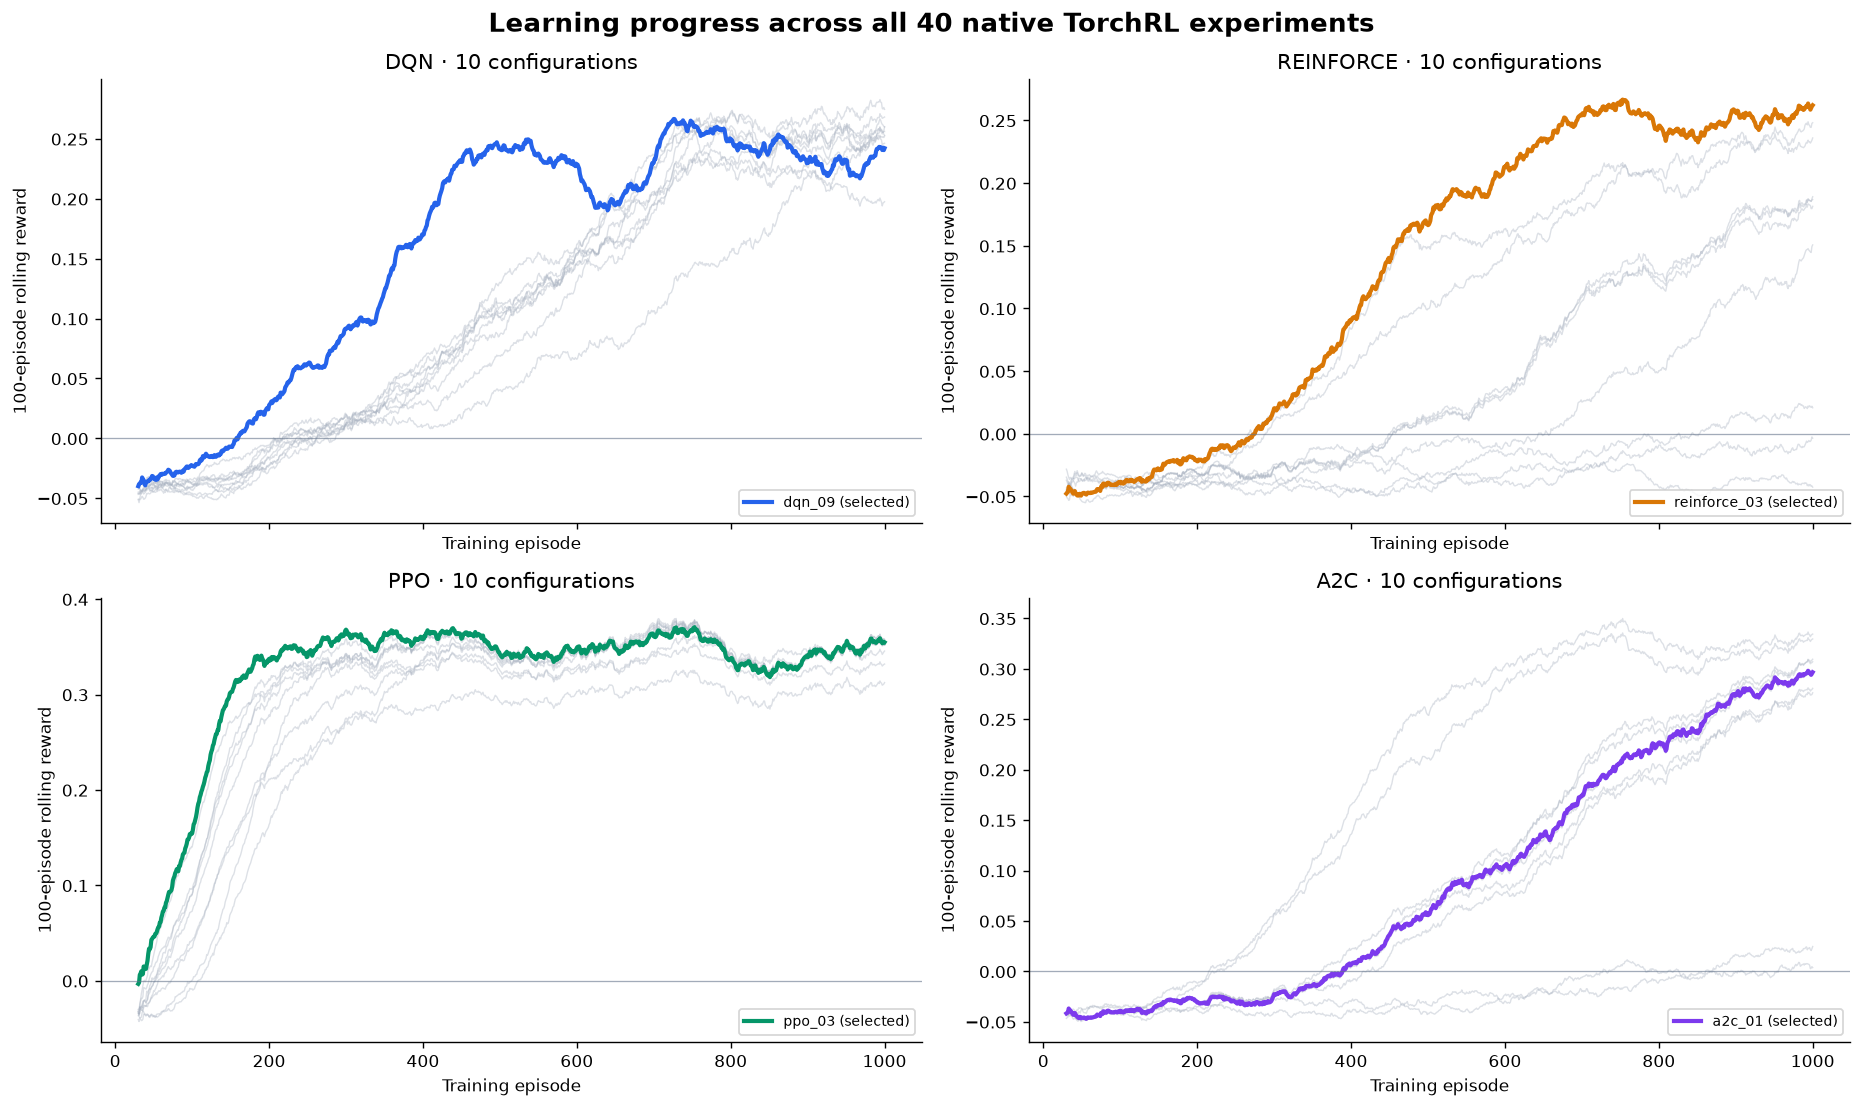

In [4]:
fig, axes = plt.subplots(2,2,figsize=(15,9),sharex=True)
for ax,algo in zip(axes.flat,ALGORITHMS):
    for run_id in sweep.loc[sweep.algorithm==algo,'run_id']:
        z=history[run_id]
        rolling=z['reward'].rolling(100,min_periods=30).mean()
        is_best=run_id==selected_ids[algo]
        ax.plot(z.episode,rolling, color=COLORS[algo] if is_best else '#a6b0bf',
                lw=2.4 if is_best else 0.8,alpha=1 if is_best else 0.38,
                label=run_id+' (selected)' if is_best else None,zorder=2 if is_best else 1)
    ax.axhline(0,color='#64748b',lw=0.75,alpha=.6)
    ax.set(title=f'{DISPLAY_NAMES[algo]} · 10 configurations',xlabel='Training episode',
           ylabel='100-episode rolling reward')
    ax.legend(loc='lower right',fontsize=8)
fig.suptitle('Learning progress across all 40 native TorchRL experiments',fontweight='bold',fontsize=15)
fig.tight_layout()
save_figure(fig,'fig01_all_40_learning_curves',
            '100-episode rolling training rewards across ten configurations per algorithm; selected run highlighted.')

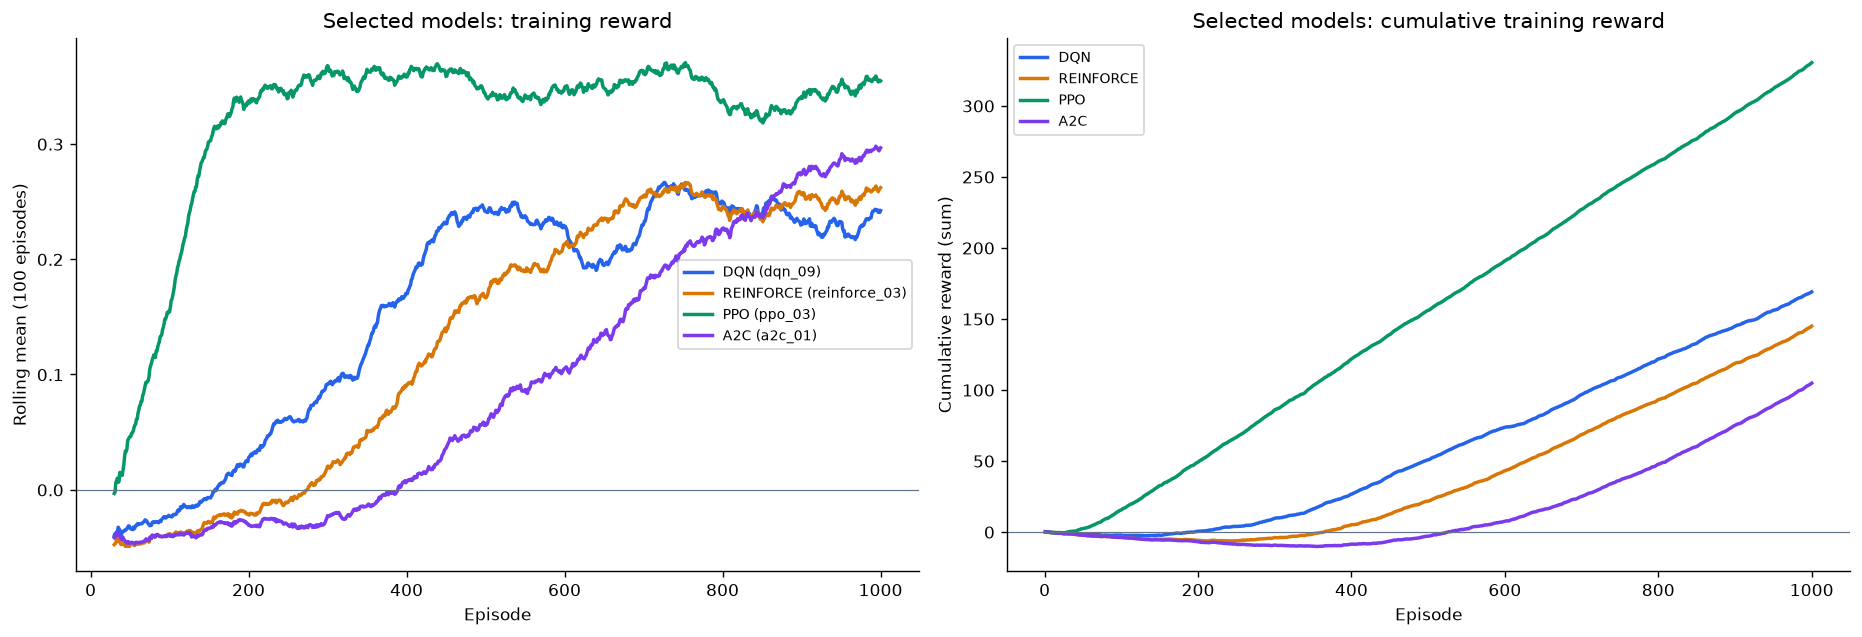

In [5]:
fig,axes=plt.subplots(1,2,figsize=(15,5.2))
for algo in ALGORITHMS:
    ep=history[selected_ids[algo]]
    rolling=ep.reward.rolling(100,min_periods=30).mean()
    axes[0].plot(ep.episode,rolling,label=f'{DISPLAY_NAMES[algo]} ({selected_ids[algo]})',
                 color=COLORS[algo],lw=2)
    axes[1].plot(ep.episode,ep.reward.cumsum(),label=DISPLAY_NAMES[algo],
                 color=COLORS[algo],lw=2)
axes[0].set(title='Selected models: training reward',xlabel='Episode',ylabel='Rolling mean (100 episodes)')
axes[1].set(title='Selected models: cumulative training reward',xlabel='Episode',ylabel='Cumulative reward (sum)')
for ax in axes: ax.legend(fontsize=8); ax.axhline(0,c='#64748b',lw=.7)
fig.tight_layout()
save_figure(fig,'fig02_selected_reward_and_cumulative',
            'Selected configurations: smoothed per-episode reward (left) and summed cumulative training reward (right).')

## 5. Stability analysis — operational measure, *not proof of convergence*

For a transparent, reproducible descriptive diagnostic, divide training into ten consecutive **100-episode blocks**. A method reaches *near-final stability* at the start of the earliest block (after episode 200) for which **at least three consecutive remaining blocks** all lie within ±0.05 cumulative reward units of the final block mean. A2C or REINFORCE may have `Not detected`. This threshold is an **illustrative heuristic**, not a theoretical convergence guarantee. It must not be described as an algorithm's true convergence episode.

,algorithm,run_id,early_100_mean,late_100_mean,change,near_final_stability_from_episode
0,dqn,dqn_09,-0.0229,0.2422,0.2651,401.0
1,reinforce,reinforce_03,-0.0382,0.2621,0.3003,501.0
2,ppo,ppo_03,0.1543,0.3548,0.2005,201.0
3,a2c,a2c_01,-0.0392,0.2966,0.3358,NaN


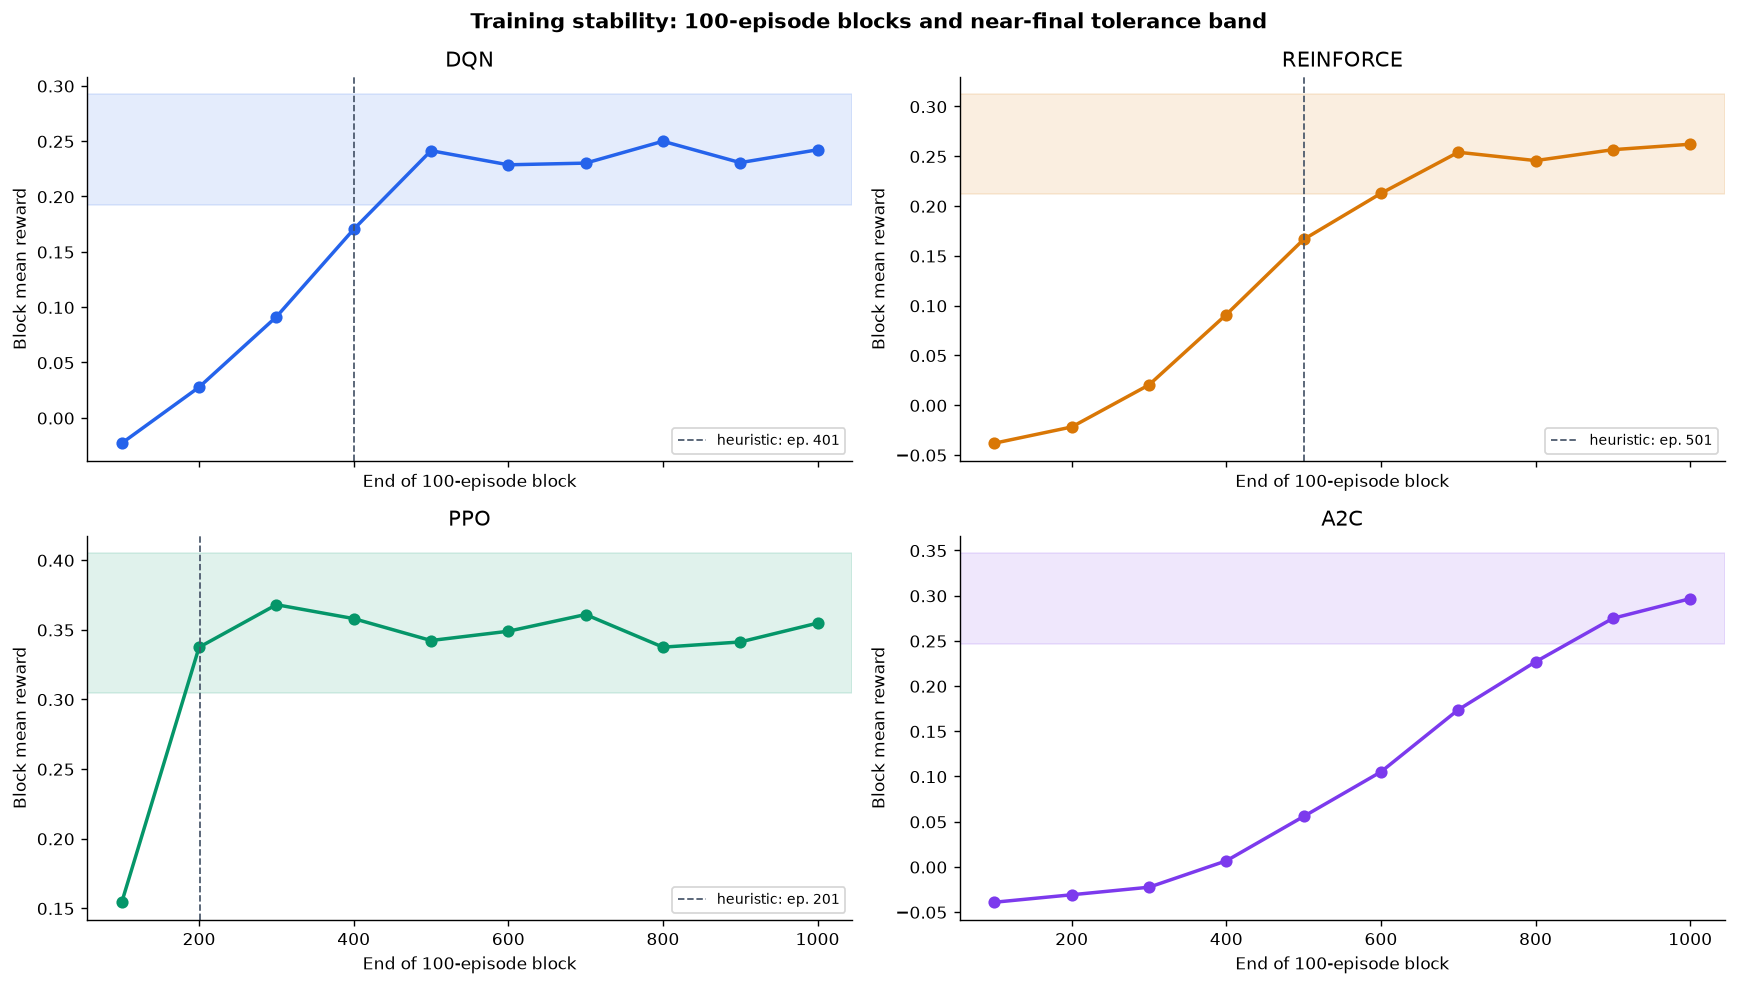

In [6]:
BLOCK=100
STABILITY_TOL=.05
stability_rows=[]
block_records=[]
for algo in ALGORITHMS:
    rid=selected_ids[algo]
    rewards=history[rid].reward.to_numpy()
    blocks=np.array([rewards[i:i+100].mean() for i in range(0,1000,100)])
    ref=blocks[-1]
    stable_idx=next((i for i in range(2,len(blocks)-2)
                     if np.all(np.abs(blocks[i:]-ref)<=STABILITY_TOL)),None)
    first= int(stable_idx*100+1) if stable_idx is not None else np.nan
    stability_rows.append({'algorithm':algo,'run_id':rid,
                           'early_100_mean':blocks[0],'late_100_mean':blocks[-1],
                           'change':blocks[-1]-blocks[0],
                           'near_final_stability_from_episode':first})
    for j,v in enumerate(blocks):
        block_records.append({'algorithm':algo,'block_start':j*100+1,'block_end':(j+1)*100,
                              'mean_training_reward':float(v)})
stability=pd.DataFrame(stability_rows)
block_df=pd.DataFrame(block_records)
stability.to_csv(TABLES/'training_stability_heuristic.csv',index=False)
block_df.to_csv(TABLES/'reward_100_episode_blocks.csv',index=False)
display(stability.round(4))
fig,axes=plt.subplots(2,2,figsize=(14,8),sharex=True)
for ax,algo in zip(axes.flat,ALGORITHMS):
    x=block_df[block_df.algorithm==algo]
    fin=x.mean_training_reward.iloc[-1]
    ax.plot(x.block_end,x.mean_training_reward,color=COLORS[algo],marker='o',lw=2)
    ax.axhspan(fin-STABILITY_TOL,fin+STABILITY_TOL,color=COLORS[algo],alpha=.12)
    found=stability.loc[stability.algorithm==algo,'near_final_stability_from_episode'].iloc[0]
    if np.isfinite(found): ax.axvline(found,color='#475569',ls='--',lw=1,label=f'heuristic: ep. {int(found)}')
    ax.set(title=DISPLAY_NAMES[algo],xlabel='End of 100-episode block',ylabel='Block mean reward')
    ax.legend(fontsize=8) if np.isfinite(found) else None
fig.suptitle('Training stability: 100-episode blocks and near-final tolerance band',fontweight='bold')
fig.tight_layout()
save_figure(fig,'fig03_stability_diagnostics',
            'Mean reward by nonoverlapping 100-episode blocks; shaded band is ±0.05 around each model’s last-block mean. Heuristic only.')

## 6. Native TorchRL objective diagnostics

DQN reports Huber TD loss; policy-gradient methods report actor/value loss terms and policy entropy. **Their losses are not on the same scale** and should not be combined into one loss ranking. PPO/A2C/REINFORCE loss/entropy values are logged **once per rollout update and copied to the affected episodes**, not 1,000 independent optimizer measurements.

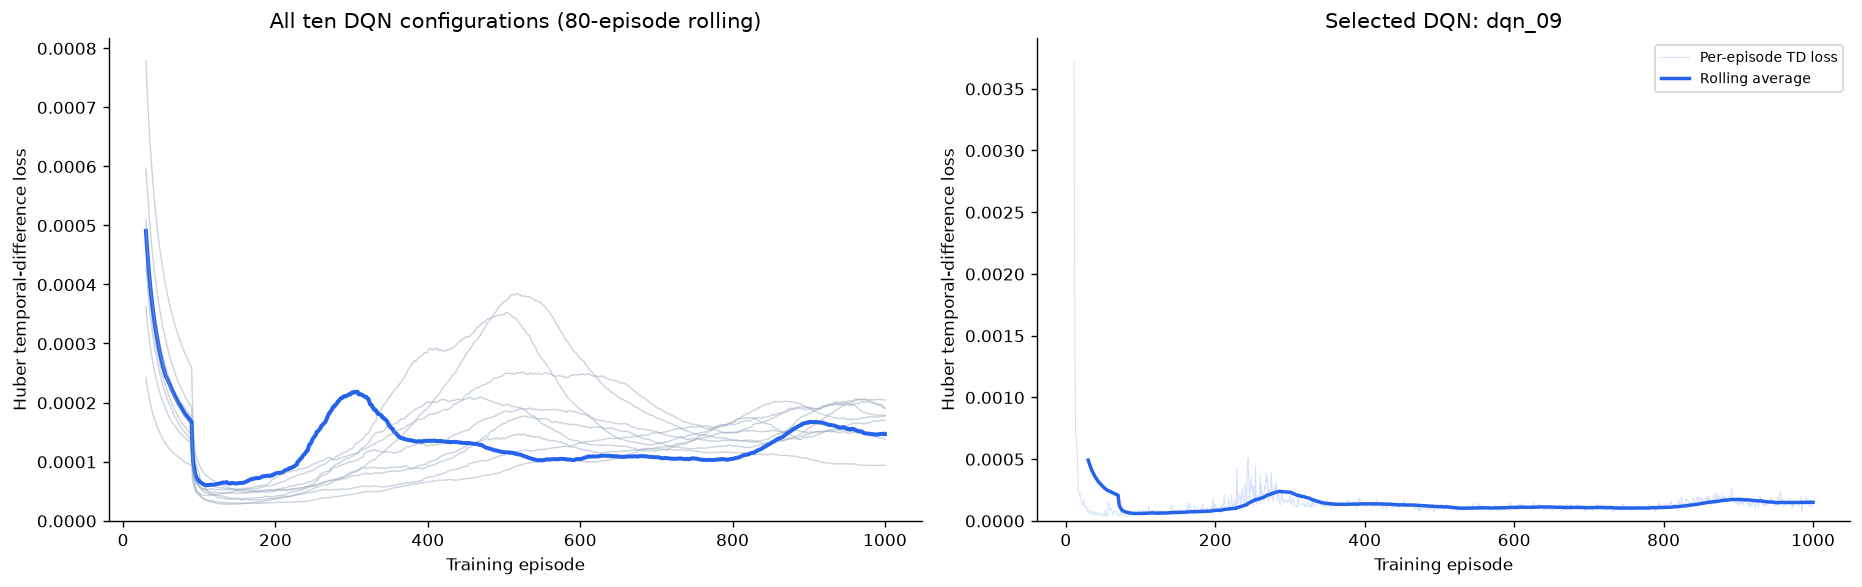

In [7]:
# DQN: show TD loss of all configurations + detailed selected run.
fig,axes=plt.subplots(1,2,figsize=(15,4.8))
for rid in sweep.loc[sweep.algorithm=='dqn','run_id']:
    ep=history[rid];is_best=rid==selected_ids['dqn']
    smooth=ep.loss.rolling(80,min_periods=20).mean()
    axes[0].plot(ep.episode,smooth,color=COLORS['dqn'] if is_best else '#94a3b8',
                 alpha=1 if is_best else .48,lw=2.3 if is_best else .8)
chosen=history[selected_ids['dqn']]
axes[1].plot(chosen.episode,chosen.loss,color=COLORS['dqn'],alpha=.19,lw=.6,label='Per-episode TD loss')
axes[1].plot(chosen.episode,chosen.loss.rolling(60,min_periods=20).mean(),color=COLORS['dqn'],lw=2,label='Rolling average')
for ax in axes:
    ax.set(xlabel='Training episode',ylabel='Huber temporal-difference loss')
    ax.set_ylim(bottom=0)
axes[0].set_title('All ten DQN configurations (80-episode rolling)')
axes[1].set_title(f'Selected DQN: {selected_ids["dqn"]}')
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig,'fig04_dqn_td_loss',
            'Native TorchRL DQNLoss smooth-L1 temporal-difference loss. Missing initial values reflect replay warmup.')

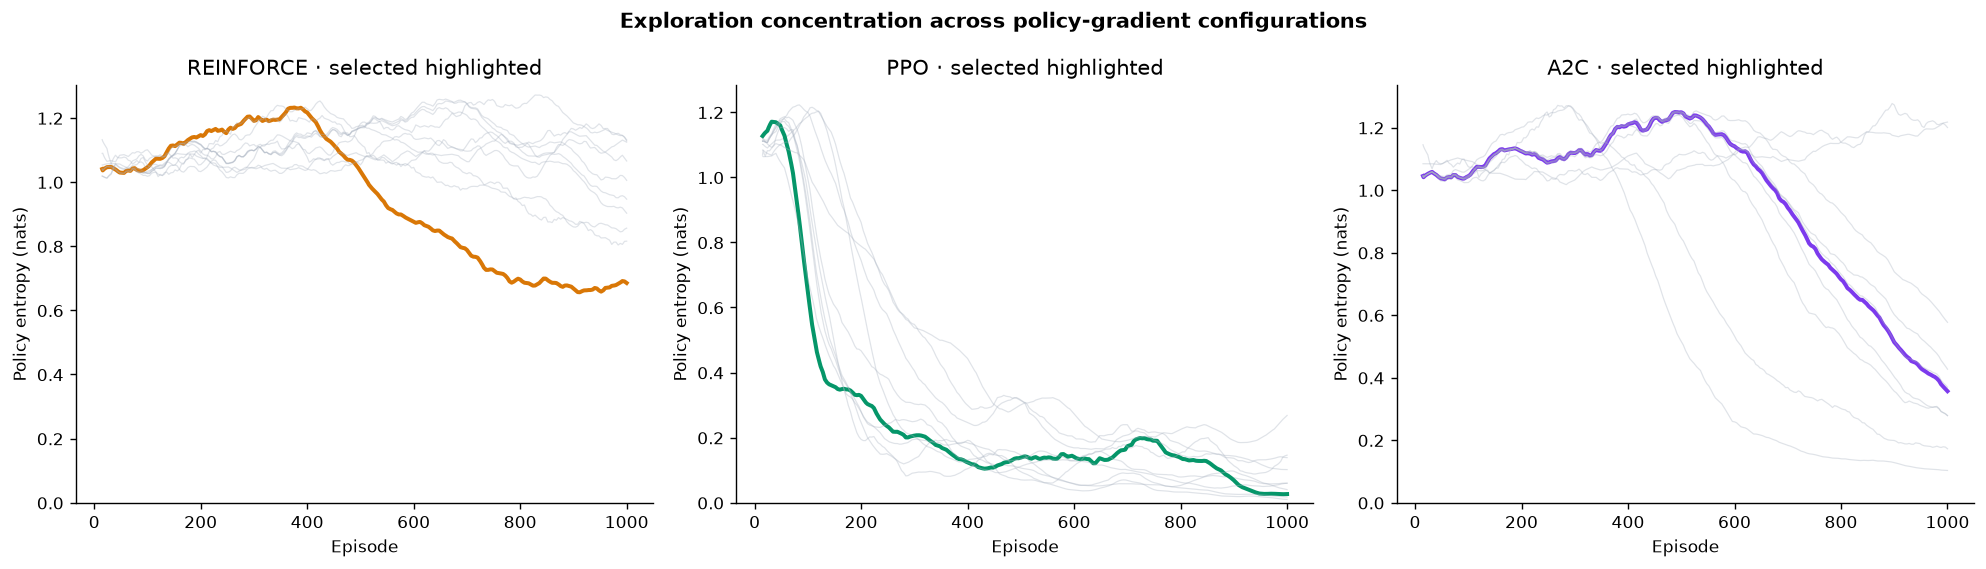

In [8]:
fig,axes=plt.subplots(1,3,figsize=(16,4.6),sharex=True)
for ax,algo in zip(axes,['reinforce','ppo','a2c']):
    for rid in sweep.loc[sweep.algorithm==algo,'run_id']:
        ep=history[rid];is_best=rid==selected_ids[algo]
        smooth=ep.entropy.rolling(60,min_periods=15).mean()
        ax.plot(ep.episode,smooth,color=COLORS[algo] if is_best else '#a6b0bf',
                lw=2.3 if is_best else .7,alpha=1 if is_best else .35)
    ax.set(title=f'{DISPLAY_NAMES[algo]} · selected highlighted',
           xlabel='Episode',ylabel='Policy entropy (nats)')
    ax.set_ylim(bottom=0)
fig.suptitle('Exploration concentration across policy-gradient configurations',fontweight='bold')
fig.tight_layout()
save_figure(fig,'fig05_policy_entropy',
            'Rolling policy entropy by episode, selected configurations highlighted; low entropy indicates concentrated action probabilities.')

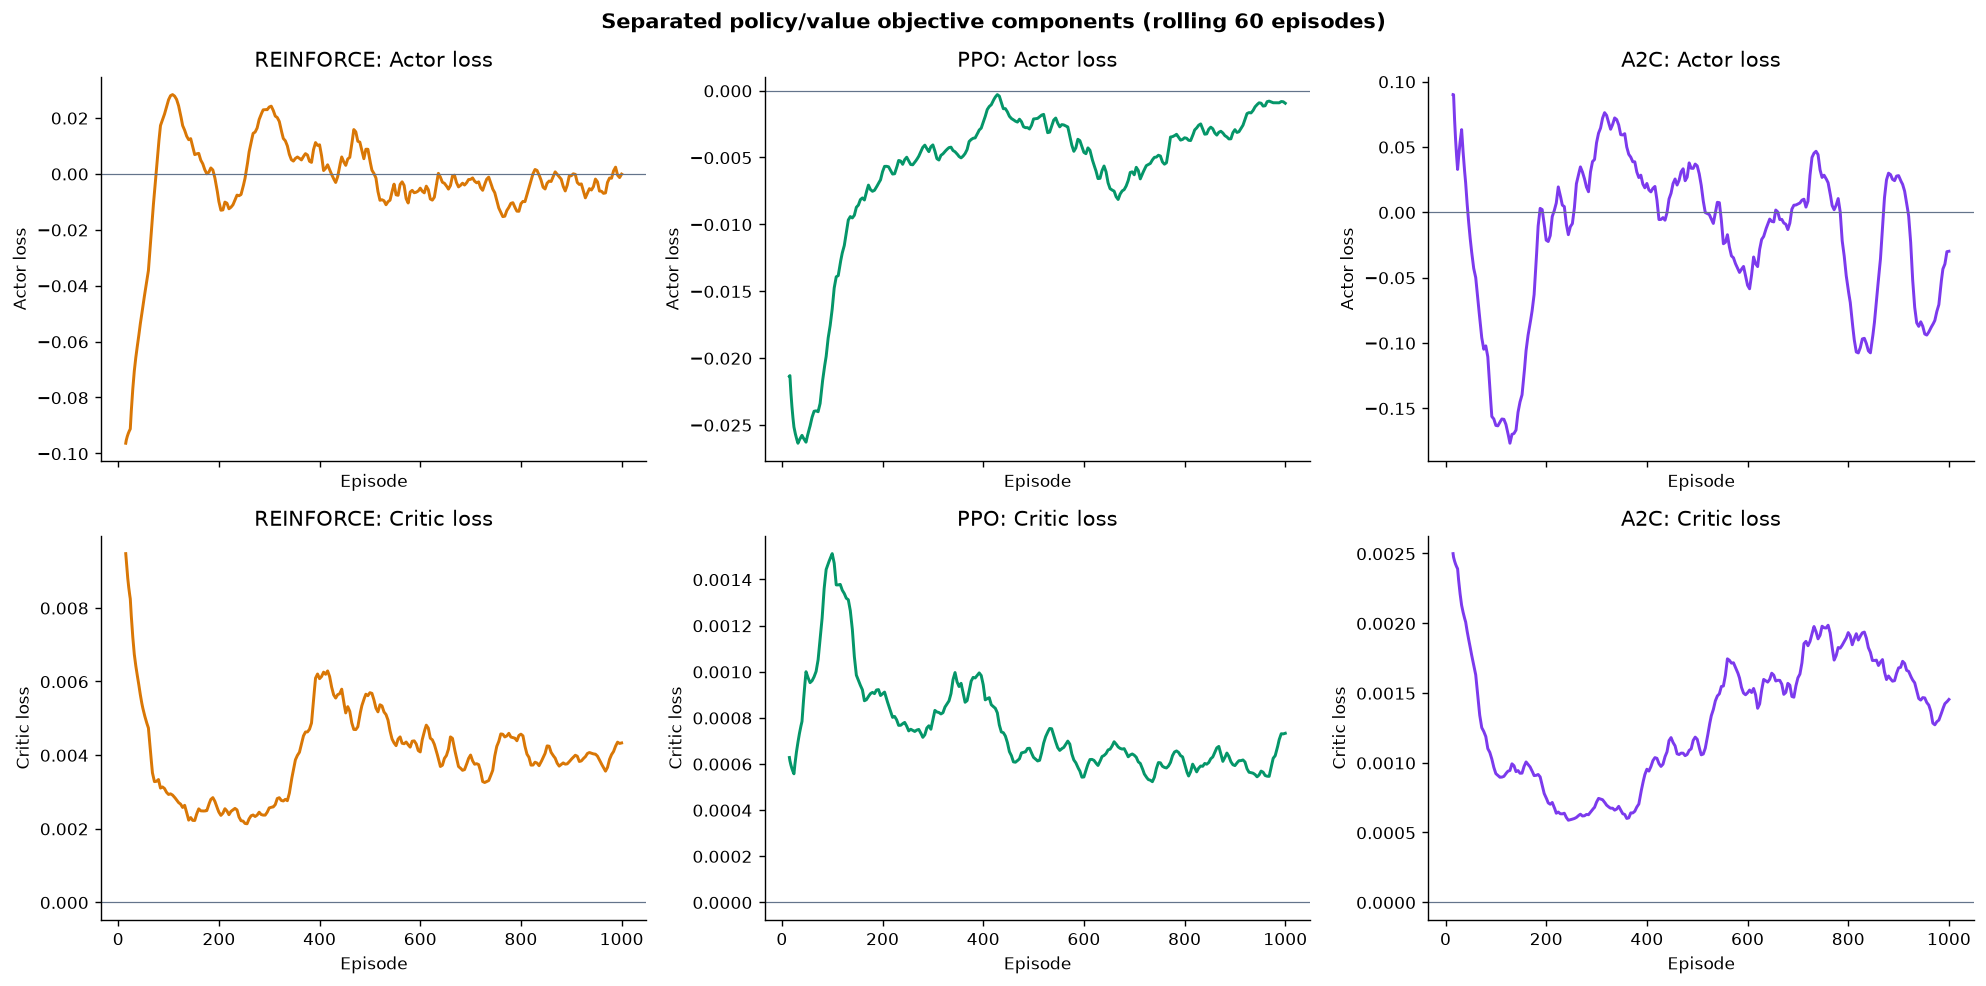

In [9]:
fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True)
for j,algo in enumerate(['reinforce','ppo','a2c']):
    x=history[selected_ids[algo]]
    for i,(field,lab) in enumerate([('actor_loss','Actor loss'),('critic_loss','Critic loss')]):
        ax=axes[i,j]
        if field not in x.columns: ax.set_visible(False);continue
        ax.plot(x.episode,x[field].rolling(60,min_periods=15).mean(),color=COLORS[algo],lw=1.7)
        ax.axhline(0,c='#64748b',lw=.7)
        ax.set(title=f'{DISPLAY_NAMES[algo]}: {lab}',xlabel='Episode',ylabel=lab)
fig.suptitle('Separated policy/value objective components (rolling 60 episodes)',fontweight='bold')
fig.tight_layout()
save_figure(fig,'fig06_actor_critic_loss',
            'Actor and critic components of native policy-gradient objectives; interpret magnitudes within, not across, algorithms.')

## 7. Hyperparameter sensitivity and complete 40-run report tables

Display **every configuration**; associate results with actual parameter choices rather than inventing causal claims. When multiple controls change together (e.g., rollout size and entropy coefficient), their individual effects cannot be isolated. The color-coded heatmap represents score difference from the first configuration **within each algorithm**.

In [10]:
parameter_columns=['lr','gamma','hidden','batch_size','replay_size','target_update',
                   'eps_decay_steps','warmup','eps_end','rollout_episodes',
                   'entropy_coeff','clip_epsilon','update_epochs','gae_lambda','value_coeff']
all_cols=['algorithm','run_id',*parameter_columns,'validation_mean_reward',
          'validation_std_reward','validation_stochastic_mean_reward','last_100_train_mean']
sweep[all_cols].to_csv(TABLES/'complete_40_hyperparameter_experiments.csv',index=False)
for algo in ALGORITHMS:
    r=sweep[sweep.algorithm==algo].copy()
    active_params=[c for c in parameter_columns if r[c].notna().any()]
    r[['run_id',*active_params,'validation_mean_reward','validation_std_reward']].to_csv(
        TABLES/f'hyperparameters_{algo}_10_runs.csv',index=False)
    display(Markdown(f'**{DISPLAY_NAMES[algo]} — 10 configurations**'))
    display(r[['run_id',*active_params,'validation_mean_reward']].round(4))

**DQN — 10 configurations**

,run_id,lr,gamma,hidden,batch_size,replay_size,target_update,eps_decay_steps,warmup,eps_end,validation_mean_reward
0,dqn_01,0.0005,0.980,64,32.0,5000.0,100.0,16000.0,250.0,NaN,0.3473
1,dqn_02,0.0002,0.980,64,32.0,5000.0,100.0,16000.0,250.0,NaN,0.3413
2,dqn_03,0.0010,0.980,64,32.0,5000.0,100.0,16000.0,250.0,NaN,0.3202
3,dqn_04,0.0005,0.950,64,32.0,5000.0,100.0,16000.0,250.0,NaN,0.3381
4,dqn_05,0.0005,0.995,64,32.0,5000.0,100.0,16000.0,250.0,NaN,0.3188
5,dqn_06,0.0005,0.980,128,32.0,5000.0,100.0,16000.0,250.0,NaN,0.2262
6,dqn_07,0.0005,0.980,64,64.0,10000.0,100.0,16000.0,250.0,NaN,0.3059
7,dqn_08,0.0005,0.980,64,32.0,5000.0,250.0,16000.0,250.0,NaN,0.3088
8,dqn_09,0.0005,0.980,64,32.0,5000.0,100.0,8000.0,250.0,NaN,0.3524
9,dqn_10,0.0005,0.980,64,32.0,5000.0,100.0,20000.0,250.0,0.1,0.2880


**REINFORCE — 10 configurations**

,run_id,lr,gamma,hidden,rollout_episodes,entropy_coeff,validation_mean_reward
10,reinforce_01,0.0005,0.980,64,8.0,0.01,0.3367
11,reinforce_02,0.0001,0.980,64,8.0,0.01,0.0484
12,reinforce_03,0.0010,0.980,64,8.0,0.01,0.3393
13,reinforce_04,0.0005,0.950,64,8.0,0.01,0.3393
14,reinforce_05,0.0005,0.995,64,8.0,0.01,0.3073
15,reinforce_06,0.0005,0.980,128,8.0,0.01,0.3367
16,reinforce_07,0.0005,0.980,32,8.0,0.01,0.2504
17,reinforce_08,0.0005,0.980,64,4.0,0.01,0.3393
18,reinforce_09,0.0005,0.980,64,16.0,0.05,0.1529
19,reinforce_10,0.0002,0.950,128,8.0,0.00,0.0000


**PPO — 10 configurations**

,run_id,lr,gamma,hidden,rollout_episodes,entropy_coeff,clip_epsilon,update_epochs,gae_lambda,validation_mean_reward
20,ppo_01,0.0005,0.98,64,8.0,0.01,0.2,4.0,0.95,0.3645
21,ppo_02,0.0002,0.98,64,8.0,0.01,0.2,4.0,0.95,0.3644
22,ppo_03,0.0010,0.98,64,8.0,0.01,0.2,4.0,0.95,0.3666
23,ppo_04,0.0005,0.98,64,8.0,0.01,0.1,4.0,0.95,0.3666
24,ppo_05,0.0005,0.98,64,8.0,0.01,0.3,4.0,0.95,0.3645
25,ppo_06,0.0005,0.98,64,8.0,0.01,0.2,2.0,0.95,0.3393
26,ppo_07,0.0005,0.98,64,8.0,0.01,0.2,8.0,0.95,0.3644
27,ppo_08,0.0005,0.98,64,8.0,0.01,0.2,4.0,0.90,0.3645
28,ppo_09,0.0005,0.98,64,4.0,0.05,0.2,4.0,0.95,0.3609
29,ppo_10,0.0005,0.98,128,16.0,0.00,0.2,4.0,0.95,0.3033


**A2C — 10 configurations**

,run_id,lr,gamma,hidden,rollout_episodes,entropy_coeff,gae_lambda,value_coeff,validation_mean_reward
30,a2c_01,0.0005,0.980,64,8.0,0.01,0.95,0.50,0.3393
31,a2c_02,0.0002,0.980,64,8.0,0.01,0.95,0.50,0.0000
32,a2c_03,0.0010,0.980,64,8.0,0.01,0.95,0.50,0.3393
33,a2c_04,0.0005,0.950,64,8.0,0.01,0.95,0.50,0.3393
34,a2c_05,0.0005,0.995,64,8.0,0.01,0.95,0.50,0.1939
35,a2c_06,0.0005,0.980,64,8.0,0.01,0.90,0.50,0.1939
36,a2c_07,0.0005,0.980,64,8.0,0.01,1.00,0.50,0.1939
37,a2c_08,0.0005,0.980,64,4.0,0.05,0.95,0.50,0.3393
38,a2c_09,0.0005,0.980,64,8.0,0.01,0.95,1.00,0.3393
39,a2c_10,0.0002,0.980,128,16.0,0.00,0.95,0.25,0.0000


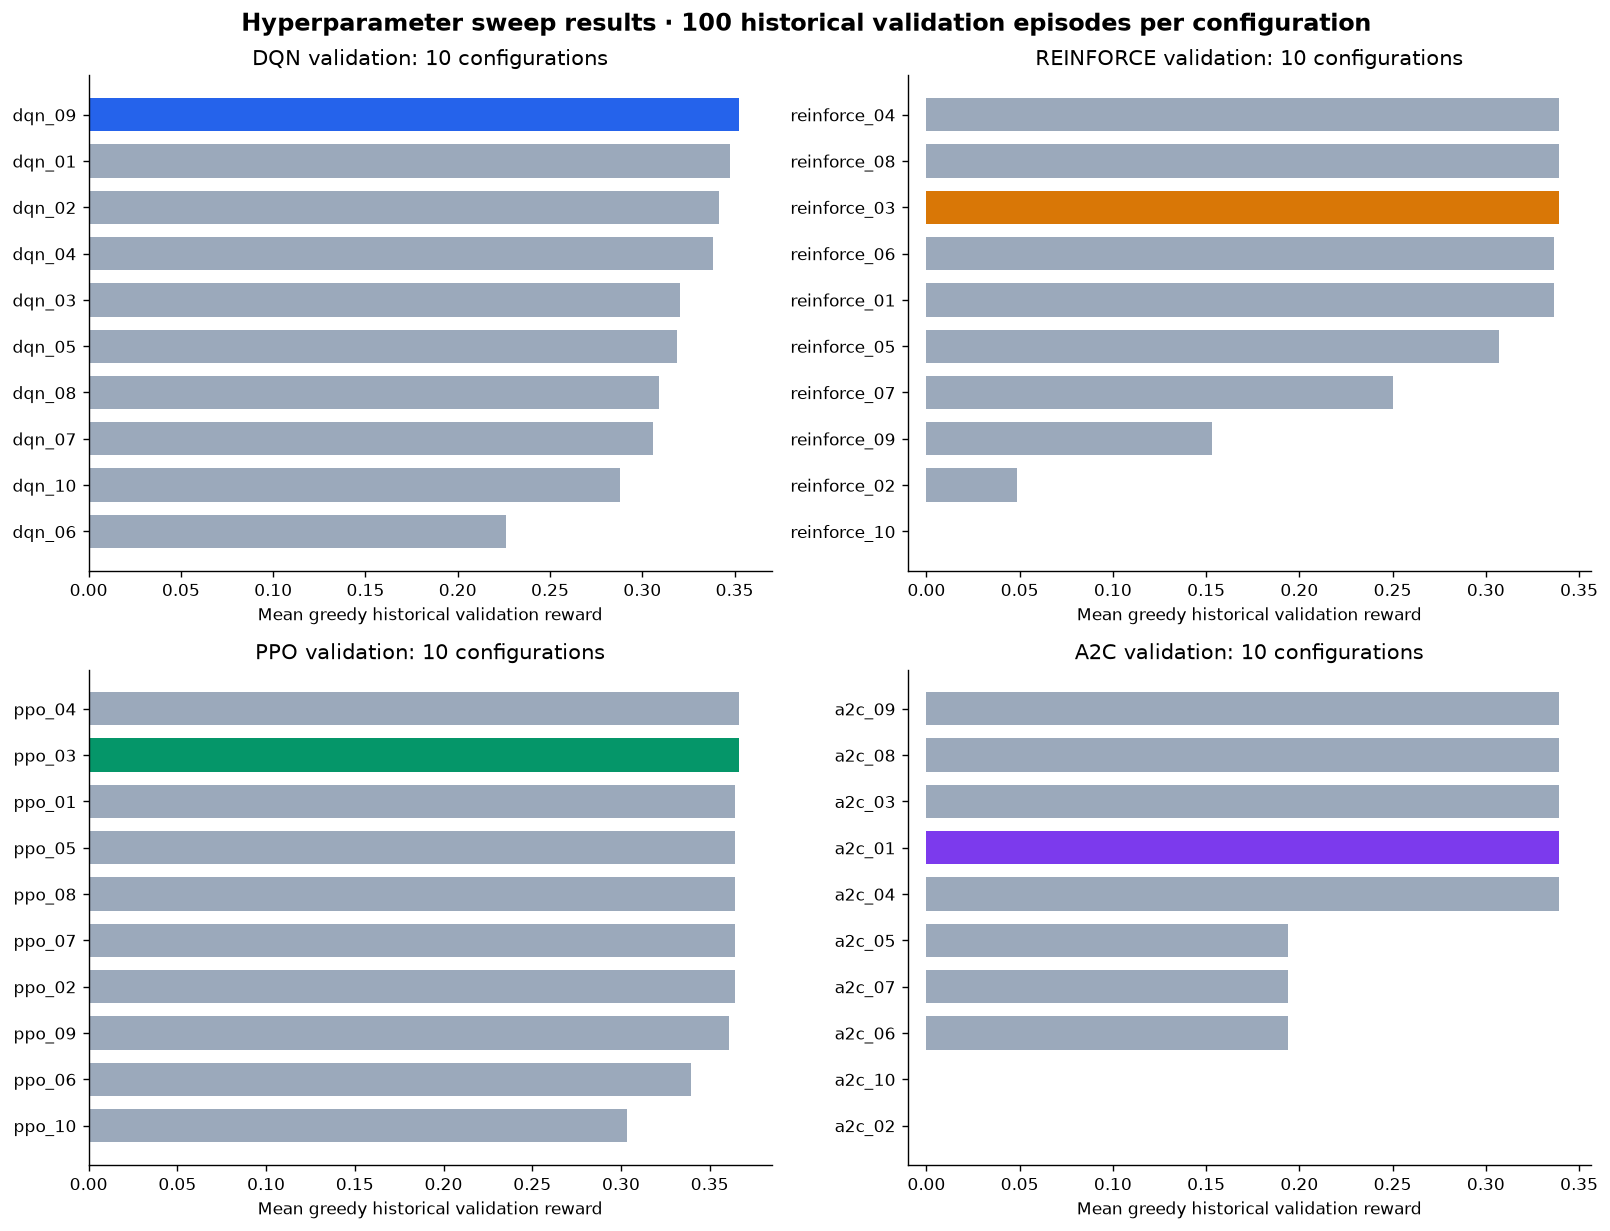

In [11]:
fig,axes=plt.subplots(2,2,figsize=(13,10))
for ax,algo in zip(axes.flat,ALGORITHMS):
    r=sweep[sweep.algorithm==algo].sort_values('validation_mean_reward')
    colors=[COLORS[algo] if x==selected_ids[algo] else '#9ba9bb' for x in r.run_id]
    ax.barh(r.run_id,r.validation_mean_reward,color=colors,height=.72)
    ax.set(title=f'{DISPLAY_NAMES[algo]} validation: 10 configurations',xlabel='Mean greedy historical validation reward')
    ax.set_xlim(left=min(0,float(r.validation_mean_reward.min())-.01))
fig.suptitle('Hyperparameter sweep results · 100 historical validation episodes per configuration',
             fontsize=14,fontweight='bold')
fig.tight_layout()
save_figure(fig,'fig07_hyperparameter_ranking',
            'Historical greedy validation mean for every configuration. Highlight indicates preselected model.')

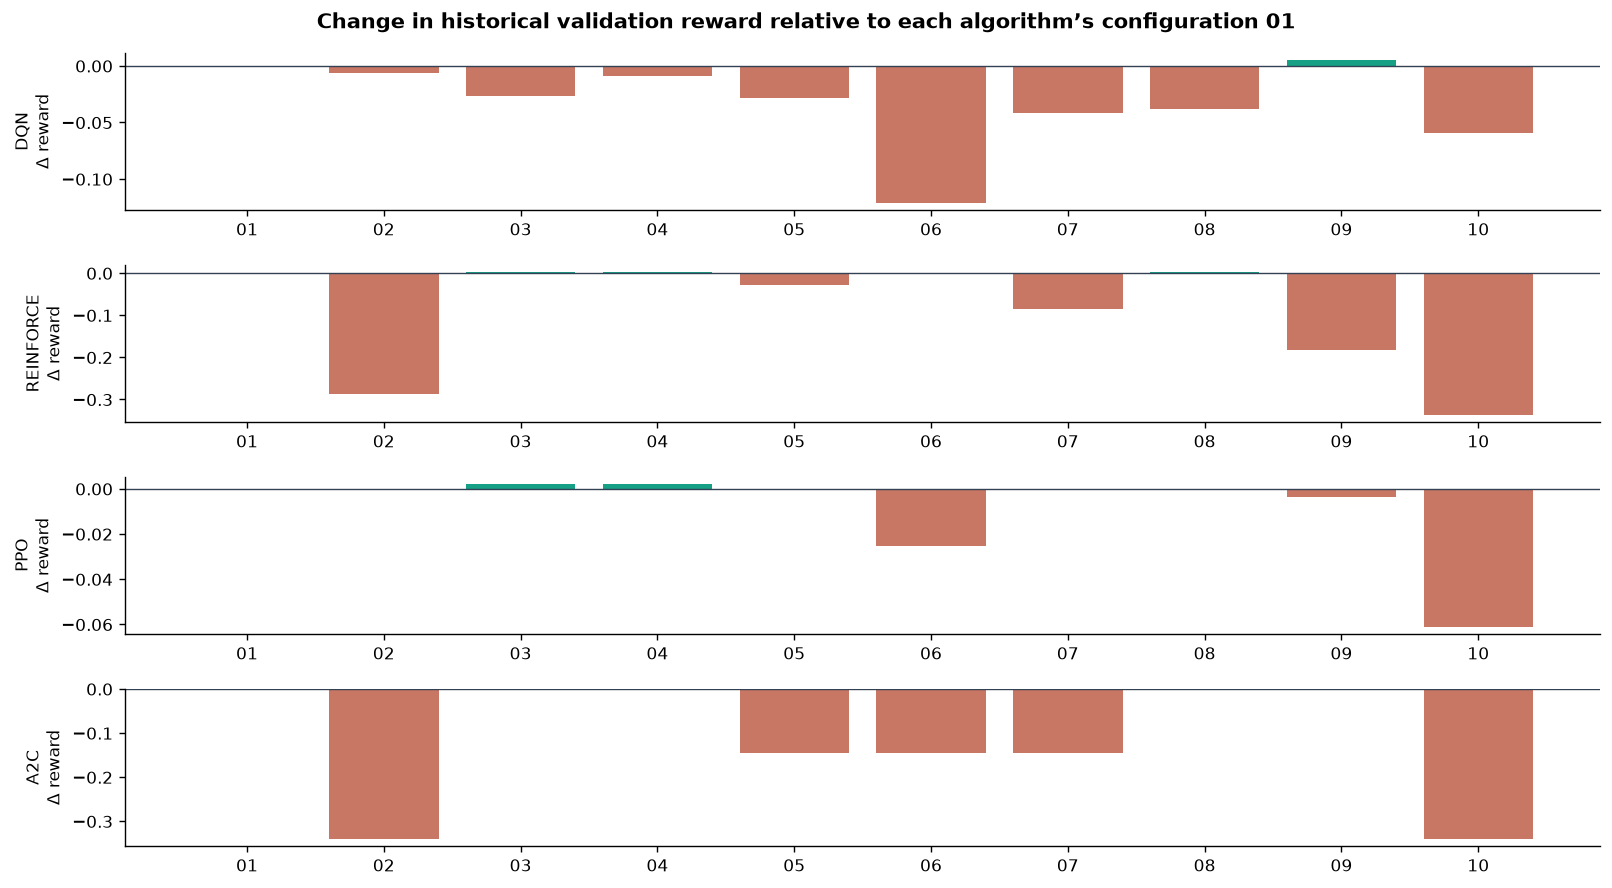

In [12]:
comparison=[]
for algo in ALGORITHMS:
    rows=sweep[sweep.algorithm==algo].sort_values('run_id')
    anchor=rows.iloc[0]
    for _,r in rows.iterrows():
        changes=[]
        for col in parameter_columns:
            old,new=anchor[col],r[col]
            if (pd.isna(old) and pd.isna(new)): continue
            if (pd.isna(old) != pd.isna(new)) or old!=new:
                changes.append(f'{col}: {old if pd.notna(old) else "default"} → {new if pd.notna(new) else "default"}')
        comparison.append({'algorithm':algo,'run_id':r.run_id,
                           'changes_vs_01':'; '.join(changes) or 'reference configuration',
                           'validation_reward':r.validation_mean_reward,
                           'difference_vs_01':r.validation_mean_reward-anchor.validation_mean_reward})
sensitivity=pd.DataFrame(comparison)
sensitivity.to_csv(TABLES/'sensitivity_vs_reference.csv',index=False)
matrix=sensitivity.pivot(index='algorithm',columns='run_id',values='difference_vs_01')
fig,axes=plt.subplots(4,1,figsize=(13,7.2),sharex=False)
for ax,algo in zip(axes,ALGORITHMS):
    r=sensitivity[sensitivity.algorithm==algo]
    values=r.difference_vs_01.values
    ax.bar(r.run_id.str.replace(algo+'_','',regex=False),values,
           color=np.where(values>=0,'#16a085','#c77764'))
    ax.axhline(0,c='#334155',lw=.8)
    ax.set_ylabel(DISPLAY_NAMES[algo]+'\nΔ reward')
fig.suptitle('Change in historical validation reward relative to each algorithm’s configuration 01',
             fontweight='bold')
fig.tight_layout()
save_figure(fig,'fig08_hyperparameter_relative_effects',
            'Within-method validation reward differences from reference run 01. Joint changes cannot isolate causal effects.')

## 8. Generalization: historical validation vs the fixed 2024 test

Model selection took place **before** the 2024 evaluation. All holdout episodes use 2024 annual HS4 signals, with new simulator seeds. Their simulated rewards should **not** be interpreted as realized 2024 investment results. Error bars below use a normal approximation to the uncertainty of the *fixed-policy mean across 100 simulated seeds*; they do **not** represent retraining variability.

,algorithm,best_run_id,historical_validation_mean,heldout_2024_mean_reward,heldout_2024_std_reward,heldout_2024_mean_net_worth,difference_2024_minus_historical
0,dqn,dqn_09,0.3524,0.3551,0.1075,129.8761,0.0027
1,reinforce,reinforce_03,0.3393,0.3434,0.1037,129.6280,0.0040
2,ppo,ppo_03,0.3666,0.3720,0.1206,130.9239,0.0054
3,a2c,a2c_01,0.3393,0.3434,0.1037,129.6280,0.0040
4,rule_based,baseline,NaN,0.2408,0.1716,120.6395,NaN
5,always_hold,baseline,NaN,0.0000,0.0000,100.0000,NaN
6,random_valid,baseline,NaN,-0.0399,0.0669,92.3671,NaN


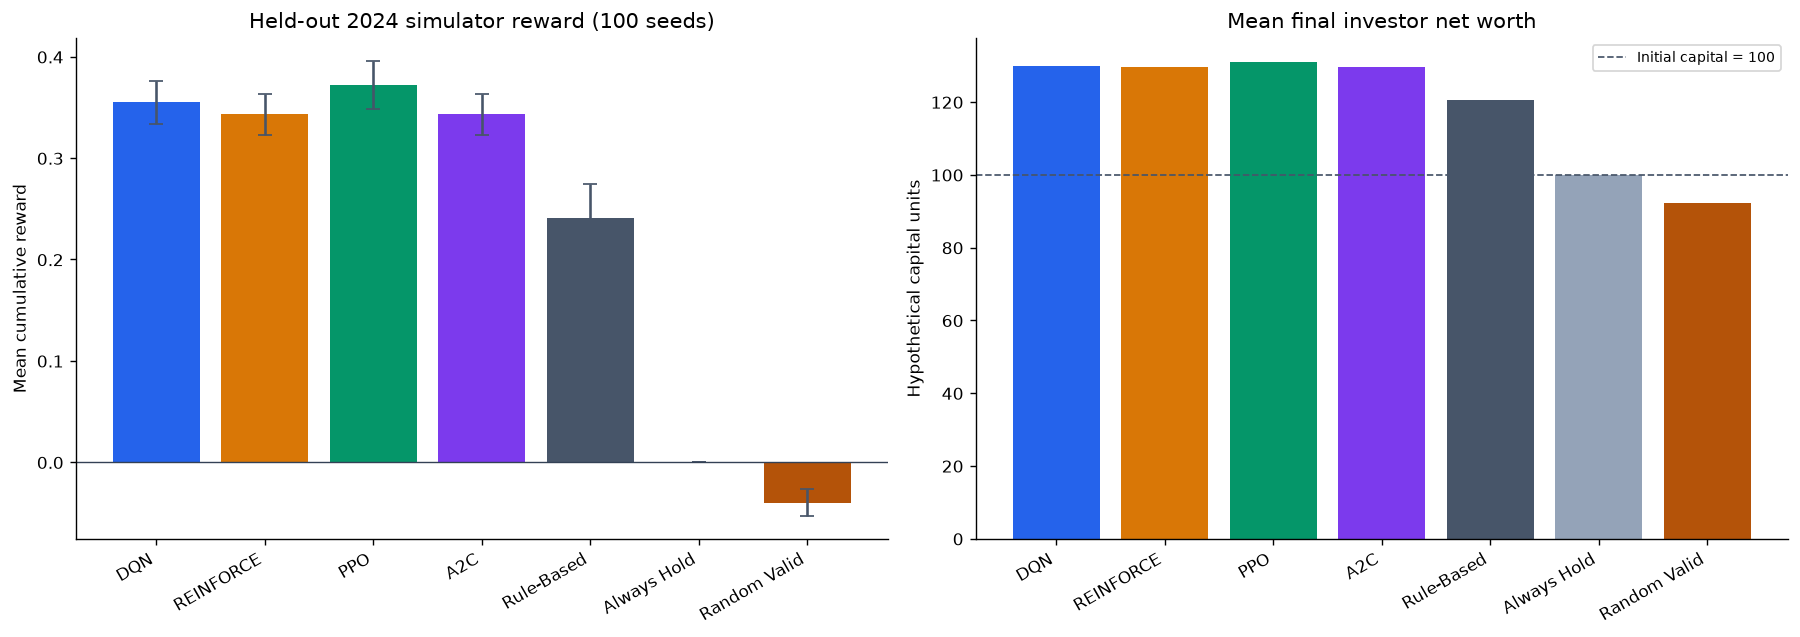

In [13]:
ordered=ALGORITHMS+['rule_based','always_hold','random_valid']
held=final.set_index('algorithm').loc[ordered].reset_index().copy()
for c in ['historical_validation_mean','heldout_2024_mean_reward',
          'heldout_2024_std_reward','heldout_2024_mean_net_worth','heldout_2024_sampled_mean']:
    held[c]=pd.to_numeric(held[c],errors='coerce')
held['mean_95pct_ci_half_width']=1.96*held.heldout_2024_std_reward/np.sqrt(N_SEEDS)
held['difference_2024_minus_historical']=held.heldout_2024_mean_reward-held.historical_validation_mean
held.drop(columns=['holdout_action_counts']).to_csv(TABLES/'final_2024_scores_with_uncertainty.csv',index=False)
display(held[['algorithm','best_run_id','historical_validation_mean','heldout_2024_mean_reward',
              'heldout_2024_std_reward','heldout_2024_mean_net_worth',
              'difference_2024_minus_historical']].round(4))
fig,axes=plt.subplots(1,2,figsize=(14.5,5.2))
labels=[DISPLAY_NAMES[a] for a in ordered]
x=np.arange(len(ordered))
axes[0].bar(x,held.heldout_2024_mean_reward,color=[COLORS[a] for a in ordered],
            yerr=held.mean_95pct_ci_half_width,capsize=4,ecolor='#475569')
axes[0].set_xticks(x,labels,rotation=30,ha='right')
axes[0].set(ylabel='Mean cumulative reward',title='Held-out 2024 simulator reward (100 seeds)')
axes[0].axhline(0,c='#334155',lw=.8)
axes[1].bar(x,held.heldout_2024_mean_net_worth,color=[COLORS[a] for a in ordered])
axes[1].set_xticks(x,labels,rotation=30,ha='right')
axes[1].set(ylabel='Hypothetical capital units',title='Mean final investor net worth')
axes[1].axhline(100,c='#475569',ls='--',lw=1,label='Initial capital = 100')
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig,'fig09_2024_holdout_and_baselines',
            'Selected policies and 3 baselines on 100 fixed 2024-seeded simulated episodes; bars are 1.96×SD/√100 approximate intervals.')

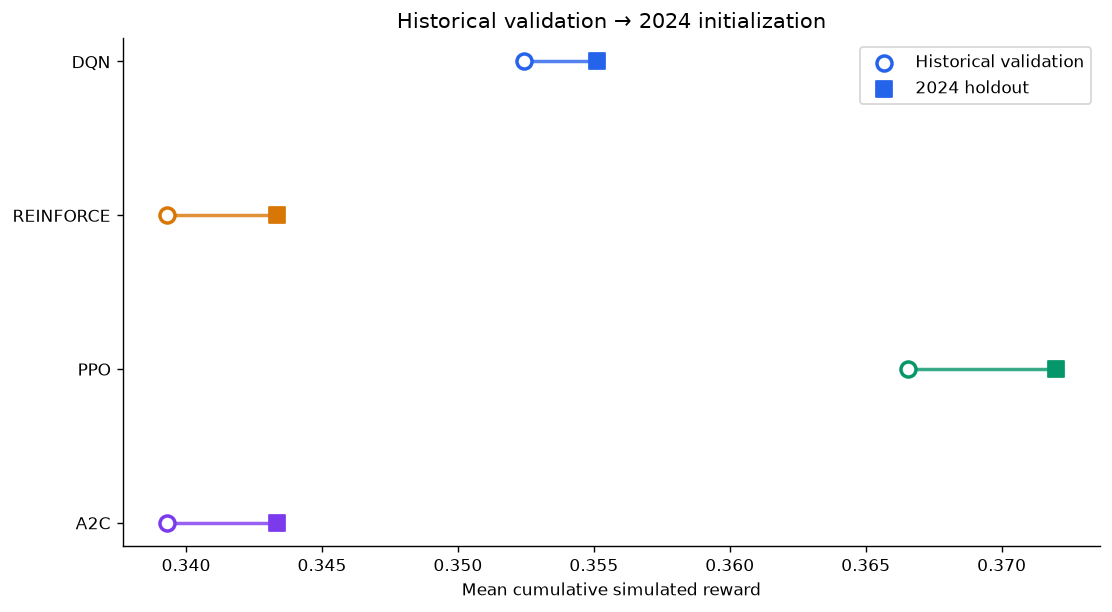

In [14]:
fig,ax=plt.subplots(figsize=(9,5))
y=np.arange(len(ALGORITHMS))
prior=held.set_index('algorithm').loc[ALGORITHMS,'historical_validation_mean']
post=held.set_index('algorithm').loc[ALGORITHMS,'heldout_2024_mean_reward']
for i,a in enumerate(ALGORITHMS):
    ax.plot([prior[a],post[a]],[i,i],lw=2,color=COLORS[a],alpha=.8)
    ax.scatter(prior[a],i,s=75,facecolor='white',edgecolor=COLORS[a],linewidth=2,label='Historical validation' if i==0 else None,zorder=3)
    ax.scatter(post[a],i,s=85,color=COLORS[a],marker='s',label='2024 holdout' if i==0 else None,zorder=3)
ax.set_yticks(y,[DISPLAY_NAMES[a] for a in ALGORITHMS]);ax.invert_yaxis()
ax.set(xlabel='Mean cumulative simulated reward',title='Historical validation → 2024 initialization')
ax.legend()
fig.tight_layout()
save_figure(fig,'fig10_validation_to_holdout_shift',
            'Greedy historical validation and held-out 2024 mean reward for the frozen selected policy in each method.')

## 9. Investment action behavior: action type and sector

All action frequencies are from the **original committed 2024 evaluation**. Four agents × 100 episodes × 24 actions = 2,400 decisions per agent. The baselines do not have saved action histograms, so they are not fabricated here. Separate sector attribution uses the documented action mapping: actions 1–4 Studies, 5–8 Pilots, 9–12 Expansions, 13–16 Exits.

action_type,Exit,Expand,Hold,Pilot,Study
algorithm,,,,,
dqn,10,252,1630,254,254
reinforce,0,200,1800,200,200
ppo,0,298,1502,300,300
a2c,0,200,1800,200,200


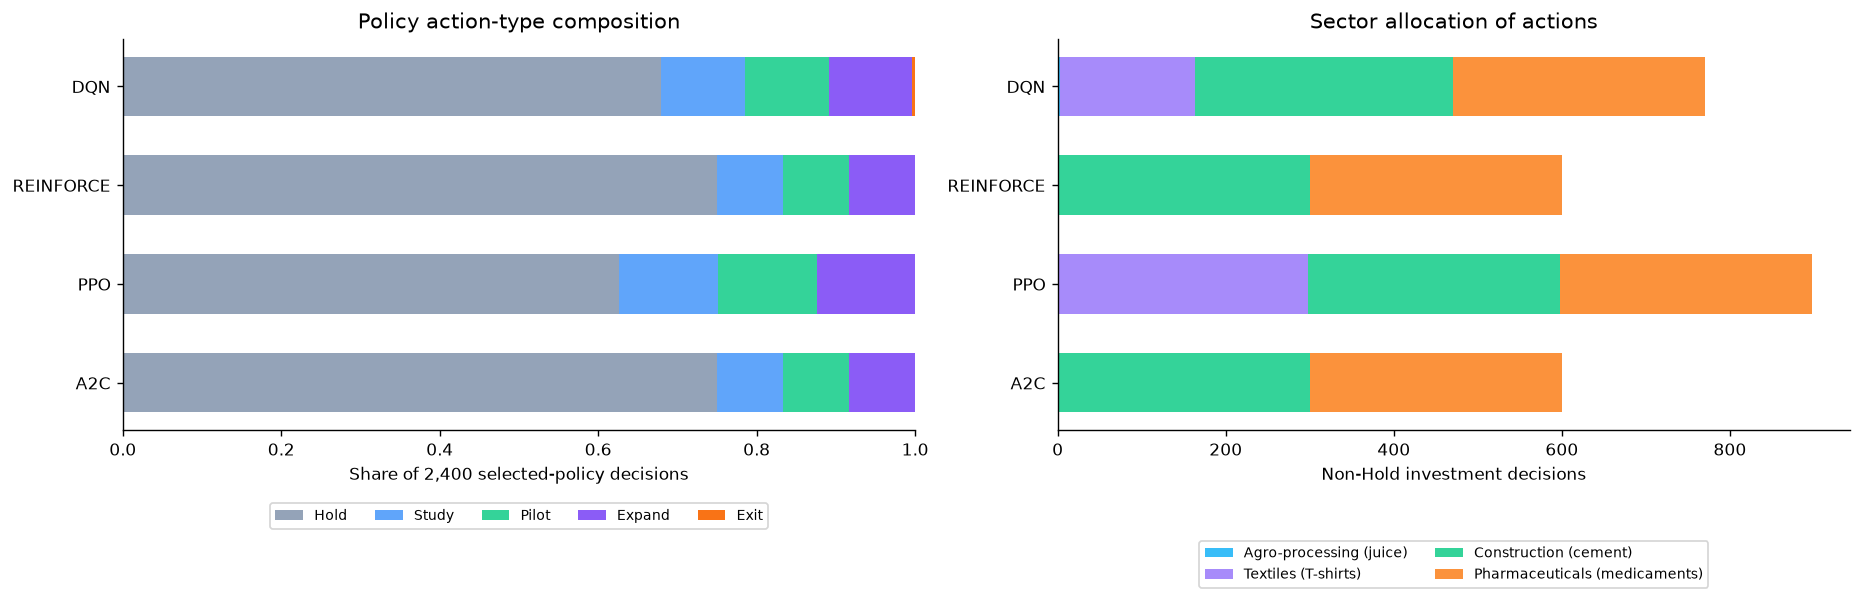

In [15]:
ACTION_GROUPS={'Hold':[0],'Study':list(range(1,5)),'Pilot':list(range(5,9)),
               'Expand':list(range(9,13)),'Exit':list(range(13,17))}
SECTOR_IDS=['agro_processing','textiles','construction_materials','pharmaceuticals']
SECTOR_LABELS=['Agro-processing (juice)','Textiles (T-shirts)','Construction (cement)','Pharmaceuticals (medicaments)']
frequency=[]; sectors=[]
for algo in ALGORITHMS:
    record=held[held.algorithm==algo].iloc[0]
    counts=json.loads(record.holdout_action_counts)
    assert len(counts)==17 and sum(counts)==2400, f'{algo}: expected 2400 decisions'
    for action_type,indices in ACTION_GROUPS.items():
        frequency.append({'algorithm':algo,'action_type':action_type,
                          'count':sum(counts[i] for i in indices),
                          'fraction':sum(counts[i] for i in indices)/2400})
    for idx,(sid,sector_label) in enumerate(zip(SECTOR_IDS,SECTOR_LABELS)):
        sectors.append({'algorithm':algo,'sector':sid,'sector_label':sector_label,
                        'decisions':int(counts[1+idx]+counts[5+idx]+counts[9+idx]+counts[13+idx])})
frequency=pd.DataFrame(frequency); sectors=pd.DataFrame(sectors)
frequency.to_csv(TABLES/'holdout_action_type_counts.csv',index=False)
sectors.to_csv(TABLES/'holdout_sector_activity.csv',index=False)
display(frequency.pivot(index='algorithm',columns='action_type',values='count').loc[ALGORITHMS])
fig,axes=plt.subplots(1,2,figsize=(15,5.3))
position=np.arange(4)
left=np.zeros(4)
act_colors={'Hold':'#94a3b8','Study':'#60a5fa','Pilot':'#34d399','Expand':'#8b5cf6','Exit':'#f97316'}
for name in ACTION_GROUPS:
    vals=frequency[frequency.action_type==name].set_index('algorithm').loc[ALGORITHMS,'fraction'].to_numpy()
    axes[0].barh(position,vals,left=left,label=name,color=act_colors[name],height=.6)
    left+=vals
axes[0].set(xlabel='Share of 2,400 selected-policy decisions',title='Policy action-type composition',xlim=(0,1))
axes[0].set_yticks(position,[DISPLAY_NAMES[a] for a in ALGORITHMS]);axes[0].invert_yaxis()
axes[0].legend(loc='lower center',bbox_to_anchor=(.5,-.27),ncol=5,fontsize=8)
mat=sectors.pivot(index='algorithm',columns='sector',values='decisions').loc[ALGORITHMS,SECTOR_IDS]
bottom=np.zeros(4)
sector_colors=['#38bdf8','#a78bfa','#34d399','#fb923c']
for label,sid,c in zip(SECTOR_LABELS,SECTOR_IDS,sector_colors):
    vals=mat[sid].to_numpy()
    axes[1].barh(position,vals,left=bottom,color=c,label=label,height=.6)
    bottom+=vals
axes[1].set(xlabel='Non-Hold investment decisions',title='Sector allocation of actions')
axes[1].set_yticks(position,[DISPLAY_NAMES[a] for a in ALGORITHMS]);axes[1].invert_yaxis()
axes[1].legend(loc='lower center',bbox_to_anchor=(.5,-.42),ncol=2,fontsize=8)
fig.tight_layout()
save_figure(fig,'fig11_actions_and_sector_activities',
            'Actions of preselected policies on the fixed 2024 simulation: 100 episodes, 24 decisions per episode. Baselines omitted: no logged action counts.')

## 10. Economic-input provenance and 2024 limits

2024 is one observed trade year, not 100 independent economic years. The demand proxies come from public UN Comtrade HS4 imports, while economic outcomes are simulated. Review `source_is_reported`, classification-mixing caveats, and the out-of-training-range indicator. In particular, a clipped demand score of 1 is **not a proof** of optimal real-world investment demand.

,sector,hs4_code,import_value_usd,demand_score,growth_signal,source_is_reported,demand_outside_training_range
0,agro_processing,2009,8554377.71,0.388521,0.496892,False,False
1,textiles,6109,4311009.08,0.210927,0.531408,False,False
2,construction_materials,2523,91717979.67,1.000000,0.594126,False,True
3,pharmaceuticals,3004,79151869.99,0.965130,0.468527,False,False


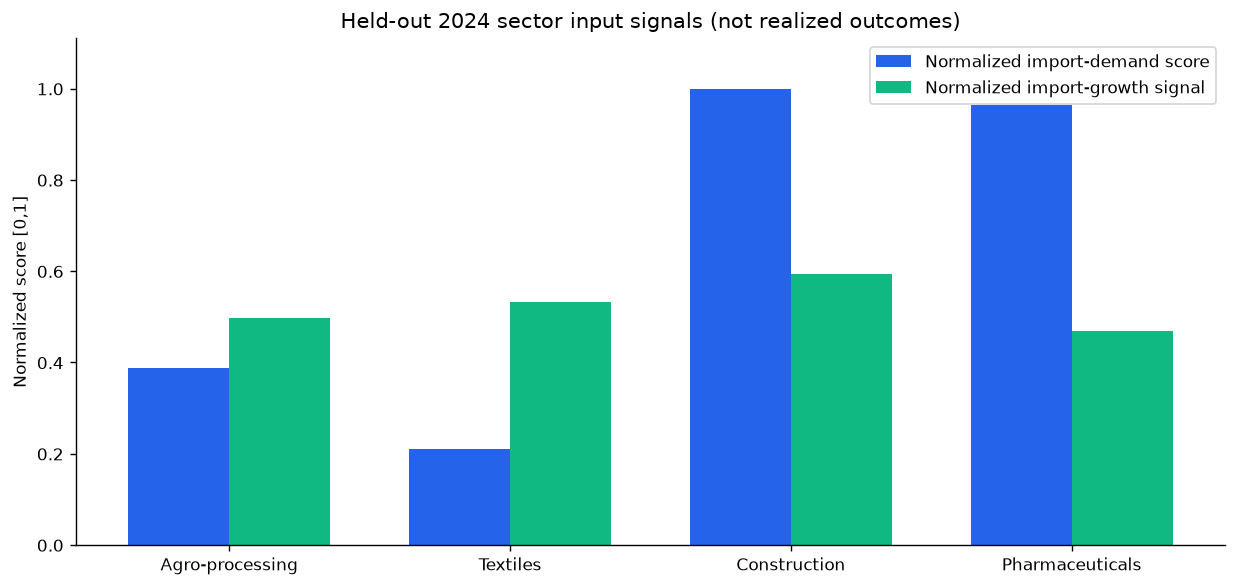

In [16]:
signals=pd.read_csv(ROOT/'data/processed/sector_signals_2024_holdout.csv')
required={'sector','hs4_code','signal_year','demand_score','growth_signal',
          'source_is_reported','demand_outside_training_range'}
assert required.issubset(signals.columns)
assert len(signals)==4 and set(signals.signal_year)=={2024}
signals.to_csv(TABLES/'2024_trade_input_provenance.csv',index=False)
display(signals[['sector','hs4_code','import_value_usd','demand_score','growth_signal',
                 'source_is_reported','demand_outside_training_range']])
fig,ax=plt.subplots(figsize=(10,4.8))
ordered_signals=signals.set_index('sector').loc[SECTOR_IDS]
x=np.arange(4);w=.36
ax.bar(x-w/2,ordered_signals.demand_score,width=w,label='Normalized import-demand score',color='#2563eb')
ax.bar(x+w/2,ordered_signals.growth_signal,width=w,label='Normalized import-growth signal',color='#10b981')
ax.set_xticks(x,['Agro-processing','Textiles','Construction','Pharmaceuticals'])
ax.set_ylim(0,1.11);ax.set(ylabel='Normalized score [0,1]',title='Held-out 2024 sector input signals (not realized outcomes)')
ax.legend()
fig.tight_layout()
save_figure(fig,'fig12_2024_trade_initial_conditions',
            '2024 HS4 demand/growth proxy scores used to initialize the held-out synthetic investment episodes; construction demand is clipped above the training range.')

## 11. Observation-space provenance table (supports the environment rubric)

The report rubric asks for all **53 observation features**, meanings, types, ranges and sources. We can export their canonical names from the simulator. Source labels below are a **starting point**: demand/growth *initialization* uses Comtrade proxies, but within-episode values still evolve synthetically. You should consult `environment/observations.py` and `docs/environment_design.md` to complete per-feature calculation and update cadence accurately—this notebook does not pretend to infer undocumented semantics from names.

In [17]:
from environment.observations import OBSERVATION_NAMES
names=list(OBSERVATION_NAMES)
assert len(names)==53
observation_table=[]
for index,name in enumerate(names):
    economic=name.endswith('.demand_score') or name.endswith('.growth_signal')
    source=('UN Comtrade HS4 at reset; synthetic monthly dynamics thereafter'
            if economic else 'Simulator state / synthetic transition / derived feature')
    observation_table.append({'index':index,'observation':name,
                              'encoding':'float32; normalized','range':'[0,1]',
                              'source_and_update_note':source,
                              'exact_meaning_and_update_rule':'REVIEW environment/observations.py'})
observation_catalog=pd.DataFrame(observation_table)
observation_catalog.to_csv(TABLES/'observation_space_53_features.csv',index=False)
print('Exported 53 observation names and preliminary provenance labels.')
display(observation_catalog.head(12))

Exported 53 observation names and preliminary provenance labels.


,index,observation,encoding,range,source_and_update_note,exact_meaning_and_update_rule
0,0,month_fraction,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
1,1,available_capital_scaled,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
2,2,committed_capital_scaled,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
3,3,employment_index,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
4,4,import_substitution_index,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
5,5,agro_processing.demand_score,float32; normalized,"[0,1]",UN Comtrade HS4 at reset; synthetic monthly dy...,REVIEW environment/observations.py
6,6,agro_processing.growth_signal,float32; normalized,"[0,1]",UN Comtrade HS4 at reset; synthetic monthly dy...,REVIEW environment/observations.py
7,7,agro_processing.supplier_concentration,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
8,8,agro_processing.feasibility_estimate,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py
9,9,agro_processing.uncertainty,float32; normalized,"[0,1]",Simulator state / synthetic transition / deriv...,REVIEW environment/observations.py


## 12. Detailed fixed-seed replay for *paired* differences — no learning

The original summary CSV contains only each model's **mean and standard deviation**. To compare two policies on the same 100 simulator seeds, we must reconstruct per-seed rewards from their frozen checkpoints. This cell runs the **same deterministic greedy inference** as `training.evaluate_final`, checks the means against the original file, and saves the per-seed results. **No gradients or optimizer steps, no altered model selection and no new holdout tuning.**

Paired-seed bootstrap intervals quantify *conditional simulated-seed variation* for these **already-trained policies**. They do not measure retraining uncertainty, and shared seeds do not guarantee perfectly matched random events once policies choose different actions.

In [18]:
if RUN_DETAILED_2024_REPLAY:
    import torch
    from torchrl.envs.utils import ExplorationType, set_exploration_type
    from environment.torchrl_adapter import IndustrialTorchRLEnv, HORIZON
    from environment.trade_env import TradeSignalEnv
    from training.networks import make_q_actor, make_policy
    from evaluation.baselines import choose_action

    torch.set_num_threads(1)
    detailed=[]
    for algo in ALGORITHMS:
        frozen=held.set_index('algorithm').loc[algo]
        config=json.loads((ROOT/'logs/training'/algo/frozen.best_run_id/'summary.json').read_text())['config']
        env=IndustrialTorchRLEnv(split='holdout')
        actor=make_q_actor(int(config['hidden']),env.action_spec) if algo=='dqn' else make_policy(int(config['hidden']),env.action_spec)
        checkpoint=torch.load(ROOT/frozen.checkpoint,map_location='cpu',weights_only=True)
        assert checkpoint['algorithm']==algo and checkpoint['framework']=='native TorchRL objectives'
        actor.load_state_dict(checkpoint['actor_state']);actor.eval()
        try:
            for seed in range(SEED_START,SEED_START+N_SEEDS):
                env.set_seed(seed)
                torch.manual_seed(seed+500_000)
                with torch.no_grad(), set_exploration_type(ExplorationType.MODE):
                    rollout=env.rollout(max_steps=HORIZON,policy=actor)
                assert rollout.numel()==HORIZON
                public=env.backend.public_state()
                detailed.append({'policy':algo,'seed':seed,
                                 'reward':float(rollout['next','reward'].sum()),
                                 'net_worth':float(public['net_worth']),
                                 'employment_index':float(public['employment_index']),
                                 'import_substitution_index':float(public['import_substitution_index']),
                                 'risk_exposure_index':float(public['risk_exposure_index'])})
        finally:
            env.close()
        print('Replayed:',DISPLAY_NAMES[algo])

    for algo in ['always_hold','random_valid','rule_based']:
        env=TradeSignalEnv(split='holdout')
        try:
            for seed in range(SEED_START,SEED_START+N_SEEDS):
                obs,info=env.reset(seed=seed)
                rng=np.random.default_rng(seed+100_000)
                reward_total=0.0
                for step in range(HORIZON):
                    action=choose_action(algo,obs,info['action_mask'],rng)
                    obs,reward,terminated,truncated,info=env.step(action)
                    reward_total+=float(reward)
                    if terminated or truncated: break
                assert step+1==HORIZON
                public=env.public_state()
                detailed.append({'policy':algo,'seed':seed,'reward':reward_total,
                                 'net_worth':float(public['net_worth']),
                                 'employment_index':float(public['employment_index']),
                                 'import_substitution_index':float(public['import_substitution_index']),
                                 'risk_exposure_index':float(public['risk_exposure_index'])})
        finally:
            env.close()
        print('Replayed baseline:',algo)
    detailed_df=pd.DataFrame(detailed)
    assert detailed_df.groupby('policy').size().eq(N_SEEDS).all()
    for alg in ordered:
        recomputed=detailed_df.loc[detailed_df.policy==alg,'reward'].mean()
        original=float(held.set_index('algorithm').loc[alg,'heldout_2024_mean_reward'])
        if not np.isclose(recomputed,original,rtol=0,atol=2e-6):
            raise AssertionError(f'{alg}: replay {recomputed:.8f} != committed result {original:.8f}. DO NOT analyze inconsistent returns.')
    detailed_df.to_csv(TABLES/'holdout_2024_per_seed_replayed.csv',index=False)
    display(detailed_df.groupby('policy',sort=False).agg(
        episodes=('seed','count'),mean_reward=('reward','mean'),
        sd_reward=('reward','std'),net_worth=('net_worth','mean'),
        employment=('employment_index','mean'),
        substitution=('import_substitution_index','mean')).round(4))
else:
    detailed_df=None
    print('Detailed replay disabled; aggregate plots above remain available.')

Replayed: DQN
Replayed: REINFORCE
Replayed: PPO
Replayed: A2C
Replayed baseline: always_hold
Replayed baseline: random_valid
Replayed baseline: rule_based


,episodes,mean_reward,sd_reward,net_worth,employment,substitution
policy,,,,,,
dqn,100,0.3551,0.1080,129.8761,0.4594,0.4034
reinforce,100,0.3434,0.1042,129.6280,0.3601,0.3818
ppo,100,0.3720,0.1212,130.9239,0.5410,0.4200
a2c,100,0.3434,0.1042,129.6280,0.3601,0.3818
always_hold,100,0.0000,0.0000,100.0000,0.0000,0.0000
random_valid,100,-0.0399,0.0672,92.3671,0.2527,0.1569
rule_based,100,0.2408,0.1725,120.6395,0.2421,0.2374


## 13. Paired effect sizes and uncertainty intervals

Bootstrap 95% confidence intervals for **PPO minus other policies**, pairing the **same 100 simulator seeds**. We report effect sizes without a categorical significance claim: the selected policies were trained once each, model selection among 10 configurations introduces selection uncertainty, and 2024 represents only one real trade-signal year.

,comparison,mean_reward_difference,ci_lower_95,ci_upper_95,n_paired_seeds,includes_zero
0,PPO − DQN,0.01685,0.00941,0.02437,100,False
1,PPO − REINFORCE,0.02863,0.01991,0.03699,100,False
2,PPO − A2C,0.02863,0.02000,0.03740,100,False
3,PPO − Rule-Based,0.13122,0.11218,0.15086,100,False
4,PPO − Always Hold,0.37198,0.34821,0.39586,100,False
5,PPO − Random Valid,0.41185,0.38811,0.43529,100,False


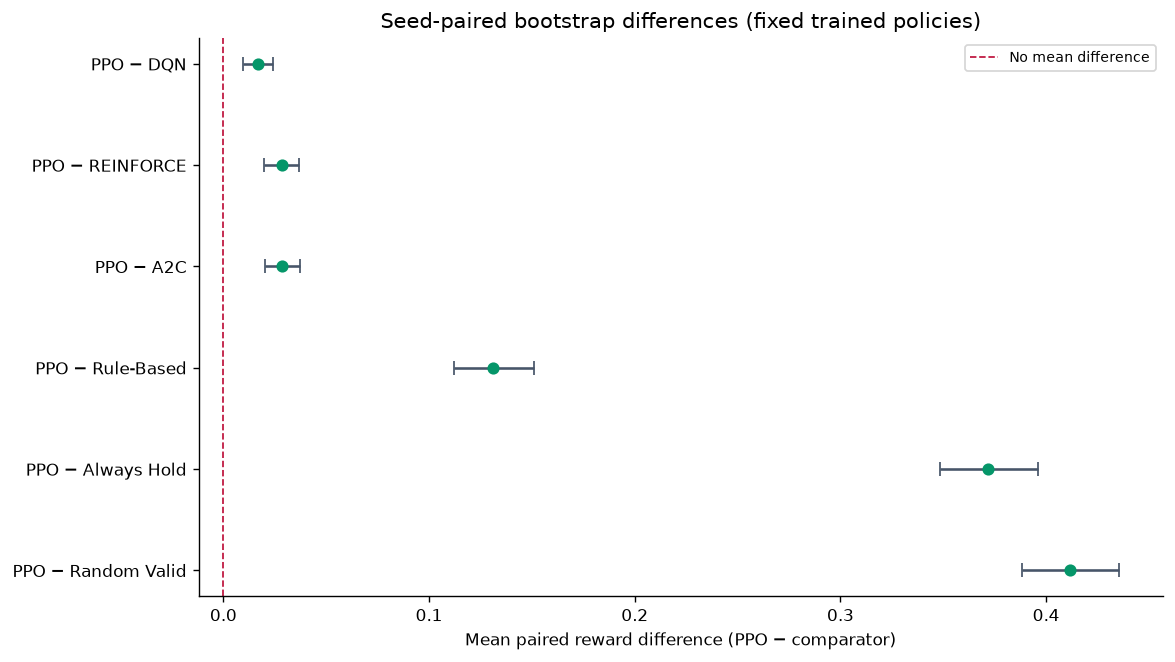

In [19]:
paired_effects=pd.DataFrame()
if detailed_df is not None:
    wide=detailed_df.pivot(index='seed',columns='policy',values='reward').sort_index()
    assert len(wide)==N_SEEDS and wide.notna().all().all()
    rng=np.random.default_rng(20261119)
    comparisons=[]
    for other in ['dqn','reinforce','a2c','rule_based','always_hold','random_valid']:
        delta=(wide['ppo']-wide[other]).to_numpy()
        boot_idx=rng.integers(0,len(delta),size=(8000,len(delta)))
        interval=np.quantile(delta[boot_idx].mean(axis=1),[.025,.975])
        comparisons.append({'comparison':f'PPO − {DISPLAY_NAMES[other]}',
                            'mean_reward_difference':float(delta.mean()),
                            'ci_lower_95':float(interval[0]),
                            'ci_upper_95':float(interval[1]),
                            'n_paired_seeds':len(delta),
                            'includes_zero':bool(interval[0]<=0<=interval[1])})
    paired_effects=pd.DataFrame(comparisons)
    paired_effects.to_csv(TABLES/'paired_bootstrap_2024_reward_differences.csv',index=False)
    display(paired_effects.round(5))
    fig,ax=plt.subplots(figsize=(9.5,5.4))
    y=np.arange(len(paired_effects))
    m=paired_effects.mean_reward_difference.to_numpy()
    lo=paired_effects.ci_lower_95.to_numpy();hi=paired_effects.ci_upper_95.to_numpy()
    ax.errorbar(m,y,xerr=[m-lo,hi-m],fmt='o',color=COLORS['ppo'],ecolor='#475569',capsize=4)
    ax.axvline(0,color='#be123c',ls='--',lw=1,label='No mean difference')
    ax.set_yticks(y,paired_effects.comparison);ax.invert_yaxis()
    ax.set(xlabel='Mean paired reward difference (PPO − comparator)',
           title='Seed-paired bootstrap differences (fixed trained policies)')
    ax.legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig,'fig13_paired_effect_bootstrap',
                'PPO minus comparator: paired 2024 simulator-seed mean reward differences with bootstrap 95% intervals. No retraining uncertainty.')
else:
    print('Run detailed replay in Section 12 to generate paired-bootstrap diagnostics.')

## 14. Risk, employment, and import substitution: development trade-offs

These metrics come from the frozen simulator's public state. A positive mission reward may result from different mixes of financial, employment and import-substitution performance. Comparing them helps interpret whether a policy only increases financial performance or also pursues simulated development goals.

,policy,net_worth,employment_index,import_substitution_index,risk_exposure_index
0,a2c,129.6280,0.3601,0.3818,0.2824
1,always_hold,100.0000,0.0000,0.0000,0.0000
2,dqn,129.8761,0.4594,0.4034,0.3259
3,ppo,130.9239,0.5410,0.4200,0.3999
4,random_valid,92.3671,0.2527,0.1569,0.0036
5,reinforce,129.6280,0.3601,0.3818,0.2824
6,rule_based,120.6395,0.2421,0.2374,0.1386


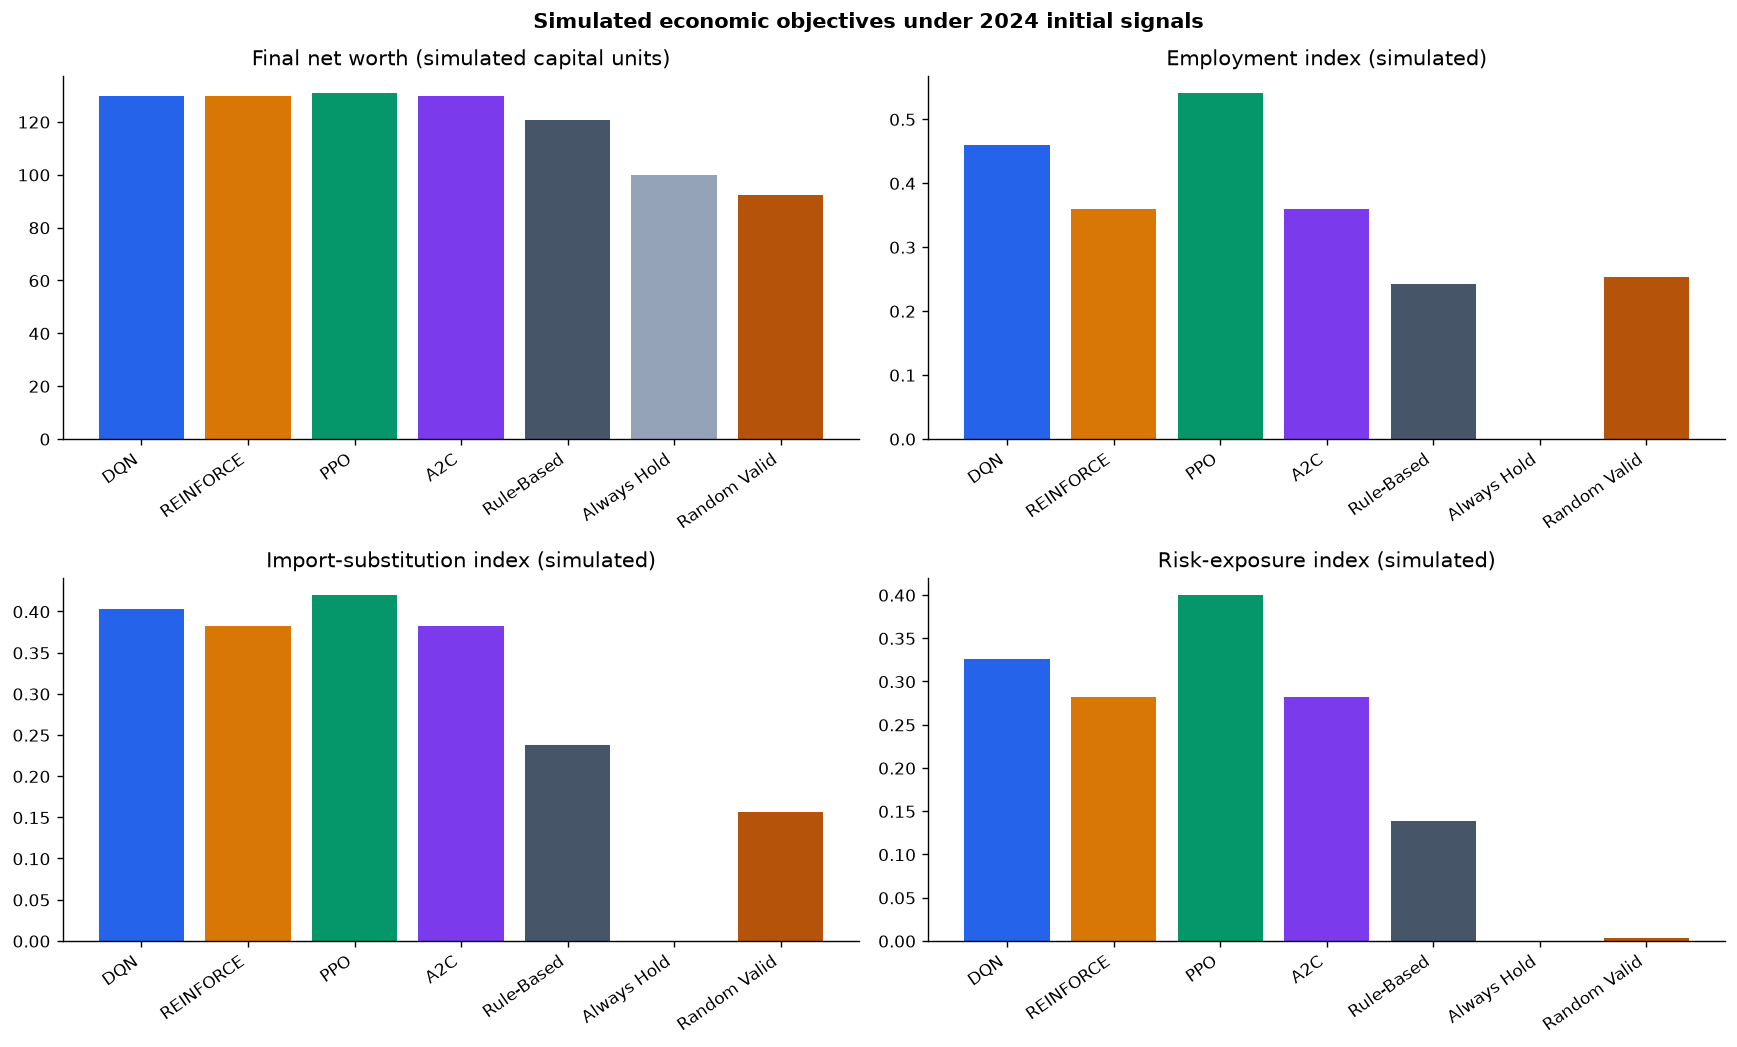

In [20]:
if detailed_df is not None:
    impact=detailed_df.groupby('policy',as_index=False)[['net_worth','employment_index',
                        'import_substitution_index','risk_exposure_index']].mean()
    impact.to_csv(TABLES/'2024_simulated_development_outcomes.csv',index=False)
    display(impact.round(4))
    impact=impact.set_index('policy').loc[ordered]
    fig,axs=plt.subplots(2,2,figsize=(14,8.5))
    for ax,(col,title) in zip(axs.flat,[('net_worth','Final net worth (simulated capital units)'),
                                         ('employment_index','Employment index (simulated)'),
                                         ('import_substitution_index','Import-substitution index (simulated)'),
                                         ('risk_exposure_index','Risk-exposure index (simulated)')]):
        ax.bar(range(len(ordered)),impact[col],color=[COLORS[x] for x in ordered])
        ax.set_xticks(range(len(ordered)),[DISPLAY_NAMES[x] for x in ordered],rotation=35,ha='right')
        ax.set_title(title)
    fig.suptitle('Simulated economic objectives under 2024 initial signals',fontweight='bold')
    fig.tight_layout()
    save_figure(fig,'fig14_simulated_development_outcomes',
                'Simulator-generated final wealth, employment, import substitution and risk across 100 held-out 2024-seeded episodes.')
else:
    print('Requires Section 12 replay.')

## 15. Representative 24-month trajectory for the report and video

Replay **PPO 03**, the fixed historical-validation winner overall, against the transparent Rule-Based baseline on exactly seed **60000**. This is an **illustrative single scenario**, not a typical or guaranteed outcome. Action descriptions and portfolio states are taken from your original simulator.

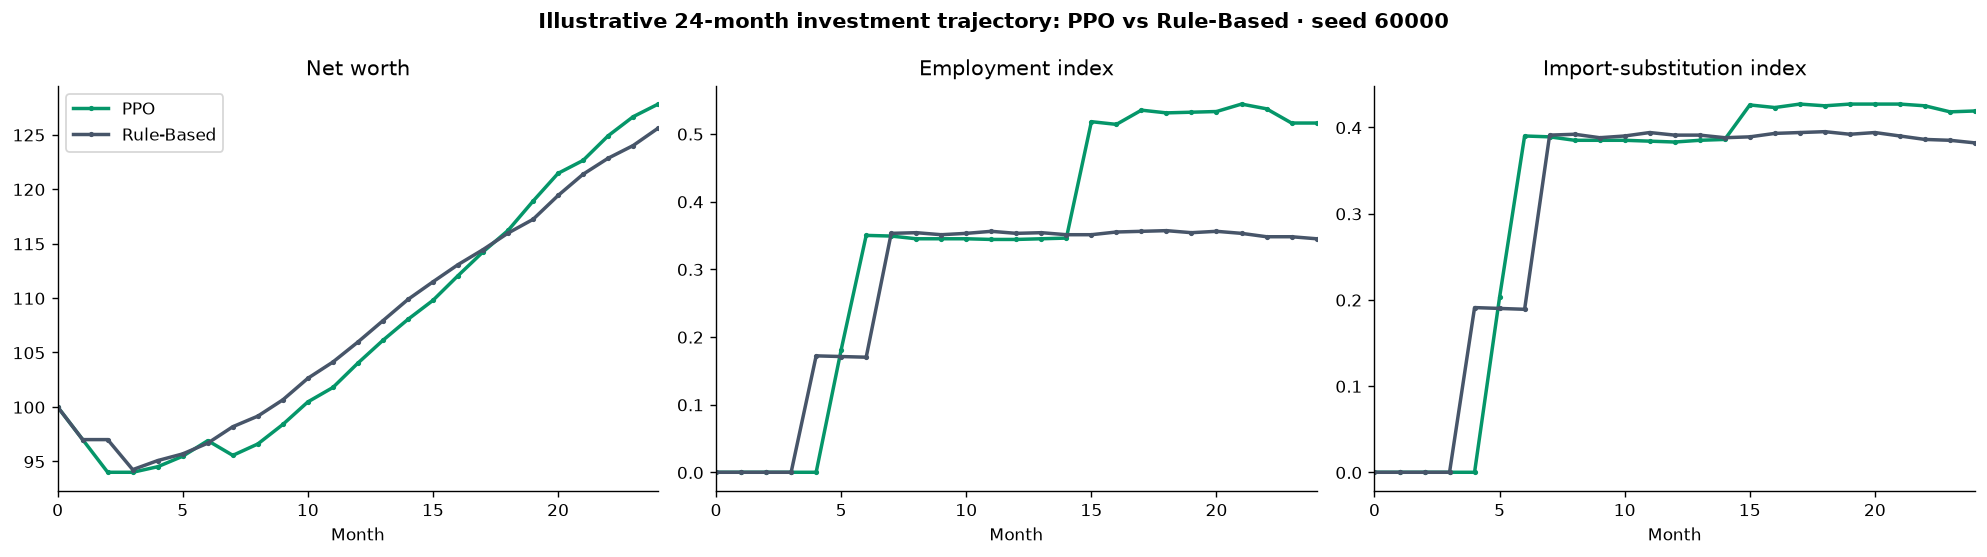

,month,action,reward,net_worth
0,0,Initial state,0.0000,100.000
1,1,Conduct feasibility study: Construction Materials,-0.0300,97.000
2,2,Conduct feasibility study: Pharmaceuticals,-0.0300,94.000
3,3,Fund pilot: Pharmaceuticals,-0.0001,94.000
4,4,Fund pilot: Construction Materials,0.0049,94.511
5,5,Expand investment: Pharmaceuticals,0.0473,95.475
6,6,Expand investment: Construction Materials,0.0484,96.905
7,7,Conduct feasibility study: Textiles,-0.0152,95.552
8,8,Fund pilot: Textiles,0.0081,96.600
9,9,Hold capital,0.0162,98.391


In [21]:
trajectory_frame=pd.DataFrame()
if detailed_df is not None:
    from tensordict import TensorDict
    from environment.actions import ACTIONS
    sample_seed=SEED_START
    chosen='ppo';rid=selected_ids[chosen]
    cfg=json.loads((ROOT/'logs/training'/chosen/rid/'summary.json').read_text())['config']
    spec_env=IndustrialTorchRLEnv(split='holdout')
    actor=make_policy(int(cfg['hidden']),spec_env.action_spec)
    spec_env.close()
    state=torch.load(ROOT/'models'/chosen/f'{rid}.pt',map_location='cpu',weights_only=True)
    actor.load_state_dict(state['actor_state']);actor.eval()

    trajectories=[]
    for policy in ['ppo','rule_based']:
        env=TradeSignalEnv(split='holdout')
        try:
            obs,info=env.reset(seed=sample_seed)
            if policy=='rule_based': rng=np.random.default_rng(sample_seed+100_000)
            initial=env.public_state()
            trajectories.append({'policy':policy,'month':0,'action_id':-1,'action':'Initial state',
                                 'reward':0.0,'net_worth':initial['net_worth'],
                                 'employment_index':initial['employment_index'],
                                 'import_substitution_index':initial['import_substitution_index'],
                                 'risk_exposure_index':initial['risk_exposure_index']})
            for month in range(1,HORIZON+1):
                if policy=='ppo':
                    td=TensorDict({'observation':torch.as_tensor(obs,dtype=torch.float32),
                                   'action_mask':torch.as_tensor(info['action_mask'],dtype=torch.bool)},batch_size=[])
                    with torch.no_grad(),set_exploration_type(ExplorationType.MODE):
                        action=int(actor(td)['action'].item())
                else:
                    action=choose_action('rule_based',obs,info['action_mask'],rng)
                obs,reward,terminated,truncated,info=env.step(action)
                v=env.public_state()
                trajectories.append({'policy':policy,'month':month,'action_id':action,
                                     'action':ACTIONS[action].description,'reward':float(reward),
                                     'net_worth':v['net_worth'],
                                     'employment_index':v['employment_index'],
                                     'import_substitution_index':v['import_substitution_index'],
                                     'risk_exposure_index':v['risk_exposure_index']})
                if terminated or truncated: break
        finally: env.close()
    trajectory_frame=pd.DataFrame(trajectories)
    trajectory_frame.to_csv(TABLES/'representative_2024_trajectory_seed60000.csv',index=False)
    fig,axarr=plt.subplots(1,3,figsize=(16,4.5))
    for policy in ['ppo','rule_based']:
        t=trajectory_frame[trajectory_frame.policy==policy]
        for ax,col,title in zip(axarr,['net_worth','employment_index','import_substitution_index'],
                                ['Net worth','Employment index','Import-substitution index']):
            ax.plot(t.month,t[col],lw=2,marker='.',ms=4,
                    color=COLORS[policy],label=DISPLAY_NAMES[policy])
            ax.set(xlabel='Month',title=title)
            ax.set_xlim(0,HORIZON)
    axarr[0].legend()
    fig.suptitle('Illustrative 24-month investment trajectory: PPO vs Rule-Based · seed 60000',
                 fontweight='bold')
    fig.tight_layout()
    save_figure(fig,'fig15_illustrative_policy_trajectory',
                'Illustrative, single-seed 24-month evolution of simulated net worth, employment and import substitution for PPO 03 vs Rule-Based.')
    display(trajectory_frame[trajectory_frame.policy=='ppo'][['month','action','reward','net_worth']].round(4).head(25))
else:
    print('Requires Section 12 replay.')

## 16. Automatically drafted evidence-based scientific discussion

The next cell creates **editable notes**, not an automatically finalized academic submission. It inserts measured results, concrete file names and explicit limitations. Read and verify the wording before including excerpts in your 7–10-page report. The official template is organized around Project Overview, Environment, System Analysis, Implementation, Results Discussion, and Conclusion. Include **A2C** in the Implementation tables even though the supplied template only shows three method tables.

In [22]:
# Derived facts from the frozen evidence only.
mean_v=sweep.groupby('algorithm').validation_mean_reward.mean()
selected_held=held.set_index('algorithm')
ppo=float(selected_held.loc['ppo','heldout_2024_mean_reward'])
rule=float(selected_held.loc['rule_based','heldout_2024_mean_reward'])
dqn=float(selected_held.loc['dqn','heldout_2024_mean_reward'])
ppo_sd=float(selected_held.loc['ppo','heldout_2024_std_reward'])
networth=float(selected_held.loc['ppo','heldout_2024_mean_net_worth'])
train_seeds_per_config=1
paragraphs=[]
paragraphs.append('# Scientific results — evidence-based discussion draft')
paragraphs.append('**Usage:** adapt these notes to the assignment report. Never present simulation scores as realized economic returns.')
paragraphs.append('## Experimental design and framework')
paragraphs.append(f'Four native TorchRL methods (DQN, REINFORCE, PPO, A2C) were each evaluated using ten predeclared hyperparameter configurations, with 1,000 complete 24-step episodes per configuration (40,000 training episodes, 960,000 simulator interactions). All models used the same 53-observation, 17-action investment simulator. A fixed training seed (42) was used for every configuration. Historical validation (2016–2023 trade-signal initialization, simulator seeds 50000–50099) determined one model per method; the 2024 holdout was assessed only afterward.')
paragraphs.append('## Rewards and leading methods')
paragraphs.append(f'The selected PPO model ({selected_ids["ppo"]}) achieved the highest held-out mean composite reward ({ppo:.4f}, SD {ppo_sd:.4f}) and mean final hypothetical net worth ({networth:.2f} from an initial 100 units). DQN ({selected_ids["dqn"]}) achieved {dqn:.4f}; the Rule-Based baseline achieved {rule:.4f}. The PPO advantage over this baseline was {ppo-rule:.4f} reward units. These are simulated outcomes conditional on the frozen policies and 2024 starting signals, not independent observations of actual investment outcomes.')
paragraphs.append('## Hyperparameter robustness')
paragraphs.append('Mean historical validation reward across the 10 configurations was '+', '.join(f'{DISPLAY_NAMES[a]} {mean_v[a]:.4f}' for a in ALGORITHMS)+'. This is descriptive robustness to the *tested* hyperparameters, not an estimate of uncertainty across independent training seeds. Some configurations changed multiple parameters simultaneously, limiting causal attribution.')
paragraphs.append('## Reward learning and convergence/stability')
for a in ALGORITHMS:
    z=stability.set_index('algorithm').loc[a]
    stab=z['near_final_stability_from_episode']
    extra=(f'The predeclared near-final tolerance was first maintained from episode {int(stab)}' if pd.notna(stab)
           else 'The predeclared sustained near-final tolerance was not detected')
    paragraphs.append(f'- **{DISPLAY_NAMES[a]} ({selected_ids[a]})**: average training reward changed from {z.early_100_mean:+.4f} (episodes 1–100) to {z.late_100_mean:+.4f} (901–1000). {extra}. This diagnostic is not a mathematical convergence proof.')
paragraphs.append('## Losses and exploration')
for a in ['reinforce','ppo','a2c']:
    z=history[selected_ids[a]].entropy
    paragraphs.append(f'- **{DISPLAY_NAMES[a]}**: first-100 mean entropy {z.iloc[:100].mean():.4f} nats; final-100 mean {z.iloc[-100:].mean():.4f} nats. Entropy is an exploration/concentration diagnostic, not itself a reward metric.')
paragraphs.append('DQN uses Huber temporal-difference loss with TorchRL replay/target updates; its first ten missing episode-loss values arise from replay warmup. Policy-gradient actor losses, critic losses and entropy bonuses have different mathematical scales and must not be compared numerically to DQN loss.')
paragraphs.append('## Generalization and statistical uncertainty')
for a in ALGORITHMS:
    row=selected_held.loc[a]
    paragraphs.append(f'- {DISPLAY_NAMES[a]}: historical mean {row.historical_validation_mean:.4f} → held-out 2024 mean {row.heldout_2024_mean_reward:.4f}; shift {row.heldout_2024_mean_reward-row.historical_validation_mean:+.4f}.')
if not paired_effects.empty:
    pairs=paired_effects.iloc[0]
    paragraphs.append(f'Seed-paired exploratory bootstrap: PPO − DQN mean reward {pairs.mean_reward_difference:+.4f}, 95% conditional bootstrap interval [{pairs.ci_lower_95:+.4f}, {pairs.ci_upper_95:+.4f}] over 100 simulation seeds. This does not account for variation from retraining.')
paragraphs.append('## Policy behavior')
for a in ALGORITHMS:
    row=frequency[frequency.algorithm==a].set_index('action_type')['count']
    paragraphs.append(f'- {DISPLAY_NAMES[a]}: '+', '.join(f'{name} {int(row[name])}' for name in ACTION_GROUPS)+f' decisions in 2,400 held-out steps.')
paragraphs.append('The 2024 economic proxy values for construction materials and medicaments are high, but the import scores are not observed returns on real factories. Portfolio and development outcomes are generated by the synthetic simulator.')
paragraphs.append('## Limitations and next work')
paragraphs.append('Only one trained policy initialization/seed was used per hyperparameter configuration. The holdout spans 100 random simulator initializations **but only one 2024 real trade-signal year**; their returns may be dependent through shared initial-year proxies. UN Comtrade preview flags are `source_is_reported=False` in the input records, with HS revision variation; construction demand is clipped above the training range. Observed imports do not validate downstream firm viability, capital return or employment. Do not assert statistically general superior algorithms without accounting for training seeds and multiple comparisons. Produce a separate interactive environment visualization and full-screen recorded demonstration as required by the assignment.')
paragraphs.append('## Figure map')
for j,item in enumerate(FIGURE_INDEX,1):
    paragraphs.append(f'{j}. **{item["figure"]}** — {item["caption"]}')
notes_text='\n\n'.join(paragraphs)+'\n'
(NOTES/'scientific_discussion_draft.md').write_text(notes_text,encoding='utf-8')
print('Saved:',NOTES/'scientific_discussion_draft.md')
display(Markdown('\n\n'.join(paragraphs[:6])))

Saved: D:\Alu docs\BSE Courses\ML Techniques II\Summative\Gaddiel_Irakoze__rl_summative\analysis_outputs\notes\scientific_discussion_draft.md


# Scientific results — evidence-based discussion draft

**Usage:** adapt these notes to the assignment report. Never present simulation scores as realized economic returns.

## Experimental design and framework

Four native TorchRL methods (DQN, REINFORCE, PPO, A2C) were each evaluated using ten predeclared hyperparameter configurations, with 1,000 complete 24-step episodes per configuration (40,000 training episodes, 960,000 simulator interactions). All models used the same 53-observation, 17-action investment simulator. A fixed training seed (42) was used for every configuration. Historical validation (2016–2023 trade-signal initialization, simulator seeds 50000–50099) determined one model per method; the 2024 holdout was assessed only afterward.

## Rewards and leading methods

The selected PPO model (ppo_03) achieved the highest held-out mean composite reward (0.3720, SD 0.1206) and mean final hypothetical net worth (130.92 from an initial 100 units). DQN (dqn_09) achieved 0.3551; the Rule-Based baseline achieved 0.2408. The PPO advantage over this baseline was 0.1312 reward units. These are simulated outcomes conditional on the frozen policies and 2024 starting signals, not independent observations of actual investment outcomes.

## 17. Export inventory and final integrity summary

Run this last. Use the `figures/` directory as figure sources in the report; use `tables/` as the auditable evidence for the hyperparameter tables and findings. Source code and trained checkpoints remain untouched.

In [23]:
pd.DataFrame(FIGURE_INDEX).to_csv(TABLES/'figure_index_and_captions.csv',index=False)
manifest={
    'generated_at_utc':datetime.now(timezone.utc).isoformat(),
    'repository_root':str(ROOT),
    'git_head':git_hash(),
    'training_runs':int(len(sweep)),
    'training_episodes':int(len(history)*1000),
    'training_steps':int(quality.steps.sum()),
    'heldout_simulation_seeds':[SEED_START,SEED_START+N_SEEDS-1],
    'holdout_real_years':[2024],
    'selected_model_ids':selected_ids,
    'detailed_replay_completed':detailed_df is not None,
    'figure_count':len(FIGURE_INDEX),
    'source_files_sha256':{
        str(x.relative_to(ROOT)):hashlib.sha256(x.read_bytes()).hexdigest()
        for x in [SWEEP_PATH,FINAL_PATH,ROOT/'data/processed/sector_signals_2024_holdout.csv']},
    'versions':{'python':platform.python_version(),'numpy':np.__version__,
                'pandas':pd.__version__,'scipy':scipy.__version__},
    'limitations':['One fixed training seed for each run',
                   '2024 is one real trade-signal year and 100 synthetic scenarios',
                   'Reward and portfolio statistics are simulated, not realized',
                   'No hyperparameter tuning or selection on the 2024 holdout']
}
(NOTES/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print(f'✔ Analysis complete. {len(FIGURE_INDEX)} figures (PNG + PDF each).')
print(f'✔ {len(list(TABLES.glob("*.csv")))} CSV evidence tables.')
print('✔ Scientific discussion draft and reproducibility manifest.')
print('Next: inspect the visualizations, write the report using the official template, and push notebooks/ + analysis_outputs/.')
display(pd.DataFrame(FIGURE_INDEX))

✔ Analysis complete. 15 figures (PNG + PDF each).
✔ 20 CSV evidence tables.
✔ Scientific discussion draft and reproducibility manifest.
Next: inspect the visualizations, write the report using the official template, and push notebooks/ + analysis_outputs/.


,figure,caption,png,pdf
0,fig01_all_40_learning_curves,100-episode rolling training rewards across te...,figures/fig01_all_40_learning_curves.png,figures/fig01_all_40_learning_curves.pdf
1,fig02_selected_reward_and_cumulative,Selected configurations: smoothed per-episode ...,figures/fig02_selected_reward_and_cumulative.png,figures/fig02_selected_reward_and_cumulative.pdf
2,fig03_stability_diagnostics,Mean reward by nonoverlapping 100-episode bloc...,figures/fig03_stability_diagnostics.png,figures/fig03_stability_diagnostics.pdf
3,fig04_dqn_td_loss,Native TorchRL DQNLoss smooth-L1 temporal-diff...,figures/fig04_dqn_td_loss.png,figures/fig04_dqn_td_loss.pdf
4,fig05_policy_entropy,"Rolling policy entropy by episode, selected co...",figures/fig05_policy_entropy.png,figures/fig05_policy_entropy.pdf
5,fig06_actor_critic_loss,Actor and critic components of native policy-g...,figures/fig06_actor_critic_loss.png,figures/fig06_actor_critic_loss.pdf
6,fig07_hyperparameter_ranking,Historical greedy validation mean for every co...,figures/fig07_hyperparameter_ranking.png,figures/fig07_hyperparameter_ranking.pdf
7,fig08_hyperparameter_relative_effects,Within-method validation reward differences fr...,figures/fig08_hyperparameter_relative_effects.png,figures/fig08_hyperparameter_relative_effects.pdf
8,fig09_2024_holdout_and_baselines,Selected policies and 3 baselines on 100 fixed...,figures/fig09_2024_holdout_and_baselines.png,figures/fig09_2024_holdout_and_baselines.pdf
9,fig10_validation_to_holdout_shift,Greedy historical validation and held-out 2024...,figures/fig10_validation_to_holdout_shift.png,figures/fig10_validation_to_holdout_shift.pdf
